# VinStroke-ECG Kaggle Notebook

**VinStroke-ECG: Hierarchical Multi-Label 12-Lead ECG Interpretation Using Multi-Representation Time-Frequency Vision Models**

Notebook này được thiết kế để chạy theo thứ tự trên Kaggle Free GPU với PTB-XL đã được add vào input.  
Mặc định notebook chạy ở `RUN_MODE = "debug"` để kiểm tra pipeline trước. Khi pipeline ổn, đổi sang `RUN_MODE = "full"` để train trên toàn bộ PTB-XL.

Mục tiêu chính:
- Dataset analysis đầy đủ.
- Manifest cho 5 diagnostic superclass: `NORM, MI, STTC, CD, HYP`.
- Rhythm label `AFIB` nếu có trong `scp_codes`.
- Visualization raw ECG, CWT, STFT và 12-lead grid.
- Train ConvNeXt-Tiny cho multi-label classification.
- Evaluation tổng và per-class.
- Calibration curves.
- Explainability heatmap.
- Ablation CWT vs STFT.
- Export report và artifact zip.

## 0. Install dependencies

Cài thêm các thư viện ECG/time-frequency cần thiết.

In [57]:
!pip install -q wfdb pywavelets scikit-learn tqdm

## 1. Setup configuration

Bắt đầu bằng debug mode:

```python
RUN_MODE = "debug"
DEBUG_LIMIT = 20
EPOCHS_DEBUG = 3
```

Khi chạy full, đổi thành:

```python
RUN_MODE = "full"
EPOCHS_FULL = 15  # hoặc 30
```

In [58]:
import os
import ast
import math
import json
import random
import shutil
import warnings
import zipfile
from pathlib import Path
from datetime import datetime
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from PIL import Image

import wfdb
import pywt
from scipy import signal
from scipy.signal import butter, filtfilt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
try:
    import timm
    print("timm version:", timm.__version__)
except Exception as e:
    print("timm is not available. Trying to install timm...")
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
    import timm
    print("timm version:", timm.__version__)
warnings.filterwarnings("ignore")

# =========================
# Runtime mode
RUN_MODE = "full"
DEBUG_LIMIT = 20

EPOCHS_DEBUG = 3
EPOCHS_FULL = 25

# =========================
# Dataset path
# =========================
PTBXL_ROOT = Path("/kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1")

# =========================
# Output paths
# =========================
WORK_DIR = Path("/kaggle/working")
REPORT_DIR = WORK_DIR / "reports"
MODEL_DIR = WORK_DIR / "models"
MANIFEST_DIR = WORK_DIR / "manifests"
DATA_DIR = WORK_DIR / "data"
CWT_DIR = DATA_DIR / "cwt_grid"
STFT_DIR = DATA_DIR / "stft_grid"
FINAL_DIR = WORK_DIR / "final_artifacts"

for d in [REPORT_DIR, MODEL_DIR, MANIFEST_DIR, DATA_DIR, CWT_DIR, STFT_DIR, FINAL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# =========================
# Training config
# =========================
SEED = 42
SAMPLING_RATE = 100
SIGNAL_LENGTH = 1000       # 10 seconds x 100 Hz
IMAGE_SIZE = 224
BATCH_SIZE_DEBUG = 4
BATCH_SIZE_FULL = 16
NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()
PRETRAINED = True       # keep False to avoid internet/pretrained weight errors
MODEL_BACKBONE = "convnextv2_base"
MODEL_NAME = MODEL_BACKBONE
LABEL_NAMES = ["NORM", "MI", "STTC", "CD", "HYP"]
RHYTHM_LABELS = ["AFIB"]

LR = 1e-4                            
WEIGHT_DECAY = 1e-4
THRESHOLD_DEFAULT = 0.5

# Time-frequency config
CWT_WAVELET = "morl"
CWT_SCALES = np.arange(1, 33)
STFT_NPERSEG = 128
STFT_NOVERLAP = 96

# Image generation config
SKIP_EXISTING_IMAGES = True
SAVE_EXAMPLE_LIMIT = 8

# Derived config
EPOCHS = EPOCHS_DEBUG if RUN_MODE == "debug" else EPOCHS_FULL
BATCH_SIZE = BATCH_SIZE_DEBUG if RUN_MODE == "debug" else BATCH_SIZE_FULL
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CONFIG = {
    "run_mode": RUN_MODE,
    "debug_limit": DEBUG_LIMIT,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "sampling_rate": SAMPLING_RATE,
    "signal_length": SIGNAL_LENGTH,
    "image_size": IMAGE_SIZE,
    "pretrained": PRETRAINED,
    "model_name": MODEL_NAME,
    "label_names": LABEL_NAMES,
    "rhythm_labels": RHYTHM_LABELS,
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "cwt_wavelet": CWT_WAVELET,
    "cwt_scales": CWT_SCALES.tolist(),
    "stft_nperseg": STFT_NPERSEG,
    "stft_noverlap": STFT_NOVERLAP,
}

print("DEVICE:", DEVICE)
print("RUN_MODE:", RUN_MODE)
print("PTBXL_ROOT exists:", PTBXL_ROOT.exists())
print("Output directory:", WORK_DIR)

timm version: 1.0.26
DEVICE: cuda
RUN_MODE: full
PTBXL_ROOT exists: True
Output directory: /kaggle/working


## 2. Reproducibility and GPU check

Set seed và kiểm tra GPU.

In [59]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

seed_everything(SEED)

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA memory allocated:", round(torch.cuda.memory_allocated(0) / 1024**3, 3), "GB")

Torch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA memory allocated: 0.959 GB


## 3. Inspect PTB-XL folder structure

Xác minh `ptbxl_database.csv`, `scp_statements.csv`, `records100`, `records500`.

In [60]:
def inspect_folder(root: Path, max_items: int = 30):
    print("Root:", root)
    if not root.exists():
        raise FileNotFoundError(f"PTBXL_ROOT does not exist: {root}")
    items = sorted(list(root.iterdir()))
    for item in items[:max_items]:
        print(" -", item.name, "/" if item.is_dir() else "")
    print("Total top-level items:", len(items))

inspect_folder(PTBXL_ROOT)

required_paths = [
    PTBXL_ROOT / "ptbxl_database.csv",
    PTBXL_ROOT / "scp_statements.csv",
    PTBXL_ROOT / "records100",
    PTBXL_ROOT / "records500",
]

for p in required_paths:
    print(f"{p.name:25s}", "OK" if p.exists() else "MISSING", str(p))

Root: /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
 - LICENSE.txt 
 - RECORDS 
 - SHA256SUMS.txt 
 - example_physionet.py 
 - ptbxl_database.csv 
 - records100 /
 - records500 /
 - scp_statements.csv 
Total top-level items: 8
ptbxl_database.csv        OK /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/ptbxl_database.csv
scp_statements.csv        OK /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/scp_statements.csv
records100                OK /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records100
records500                OK /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500


## 4. Load metadata and SCP statements

Đọc metadata PTB-XL và bảng mô tả SCP statements.

In [61]:
ptbxl_df = pd.read_csv(PTBXL_ROOT / "ptbxl_database.csv")
scp_df = pd.read_csv(PTBXL_ROOT / "scp_statements.csv", index_col=0)

print("ptbxl_database shape:", ptbxl_df.shape)
print("scp_statements shape:", scp_df.shape)
display(ptbxl_df.head())
display(scp_df.head())

print("ptbxl_database columns:")
print(ptbxl_df.columns.tolist())

print("\nscp_statements columns:")
print(scp_df.columns.tolist())

ptbxl_database shape: (21837, 28)
scp_statements shape: (71, 12)


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


ptbxl_database columns:
['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']

scp_statements columns:
['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class', 'diagnostic_subclass', 'Statement Category', 'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code', 'DICOM Code']


## 5. Create manifest for diagnostic superclass and AFIB

Mapping:
- Parse `scp_codes`.
- Nếu code có `diagnostic == 1`, map `diagnostic_class` vào `NORM, MI, STTC, CD, HYP`.
- Nếu code là `AFIB`, tạo rhythm label `AFIB`.
- Split theo `strat_fold`: 1–8 train, 9 validation, 10 test.

In [62]:
def parse_scp_codes(x):
    """Parse SCP code dictionary from PTB-XL metadata."""
    if isinstance(x, dict):
        return x
    if pd.isna(x):
        return {}
    try:
        return ast.literal_eval(x)
    except Exception:
        return {}

def map_diagnostic_superclasses(scp_codes: dict, scp_meta: pd.DataFrame, labels=LABEL_NAMES):
    """Map SCP codes to PTB-XL diagnostic superclasses."""
    out = {label: 0 for label in labels}
    for code in scp_codes.keys():
        if code not in scp_meta.index:
            continue
        row = scp_meta.loc[code]
        diagnostic_flag = row.get("diagnostic", 0)
        diagnostic_class = row.get("diagnostic_class", None)
        try:
            is_diag = int(diagnostic_flag) == 1
        except Exception:
            is_diag = False
        if is_diag and diagnostic_class in out:
            out[diagnostic_class] = 1
    return out

def map_rhythm_labels(scp_codes: dict, rhythm_labels=RHYTHM_LABELS):
    out = {label: 0 for label in rhythm_labels}
    for label in rhythm_labels:
        if label in scp_codes:
            out[label] = 1
    return out

def split_from_fold(fold):
    if fold in list(range(1, 9)):
        return "train"
    if fold == 9:
        return "val"
    if fold == 10:
        return "test"
    return "unknown"

def create_manifest(ptbxl_df: pd.DataFrame, scp_df: pd.DataFrame):
    df = ptbxl_df.copy()
    df["scp_dict"] = df["scp_codes"].apply(parse_scp_codes)
    df["split"] = df["strat_fold"].apply(split_from_fold)

    diag_rows = []
    rhythm_rows = []
    top_scp_rows = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Mapping labels"):
        diag_rows.append(map_diagnostic_superclasses(row["scp_dict"], scp_df))
        rhythm_rows.append(map_rhythm_labels(row["scp_dict"]))
        top_scp_rows.append("|".join(list(row["scp_dict"].keys())))

    diag_df = pd.DataFrame(diag_rows)
    rhythm_df = pd.DataFrame(rhythm_rows)

    manifest = pd.concat([df.reset_index(drop=True), diag_df, rhythm_df], axis=1)
    manifest["all_scp_codes"] = top_scp_rows

    manifest["record_path"] = manifest["filename_lr"].apply(lambda x: str(PTBXL_ROOT / x))
    manifest["ecg_id"] = manifest["ecg_id"].astype(int)
    manifest["num_superclass_labels"] = manifest[LABEL_NAMES].sum(axis=1)
    manifest["has_any_superclass"] = (manifest["num_superclass_labels"] > 0).astype(int)

    manifest_targets = manifest[manifest["has_any_superclass"] == 1].copy()
    return manifest, manifest_targets

manifest_all, manifest = create_manifest(ptbxl_df, scp_df)

manifest_all_path = MANIFEST_DIR / "manifest_all_records.csv"
manifest_path = MANIFEST_DIR / "manifest_superclass_records.csv"
manifest_all.to_csv(manifest_all_path, index=False)
manifest.to_csv(manifest_path, index=False)

print("All manifest shape:", manifest_all.shape)
print("Training manifest with superclass labels shape:", manifest.shape)
print("Saved:", manifest_all_path)
print("Saved:", manifest_path)
display(manifest[["ecg_id", "patient_id", "strat_fold", "split", "filename_lr"] + LABEL_NAMES + RHYTHM_LABELS].head())

Mapping labels:   0%|          | 0/21837 [00:00<?, ?it/s]

All manifest shape: (21837, 40)
Training manifest with superclass labels shape: (21430, 40)
Saved: /kaggle/working/manifests/manifest_all_records.csv
Saved: /kaggle/working/manifests/manifest_superclass_records.csv


,ecg_id,patient_id,strat_fold,split,filename_lr,NORM,MI,STTC,CD,HYP,AFIB
0,1,15709.0,3,train,records100/00000/00001_lr,1,0,0,0,0,0
1,2,13243.0,2,train,records100/00000/00002_lr,1,0,0,0,0,0
2,3,20372.0,5,train,records100/00000/00003_lr,1,0,0,0,0,0
3,4,17014.0,3,train,records100/00000/00004_lr,1,0,0,0,0,0
4,5,17448.0,4,train,records100/00000/00005_lr,1,0,0,0,0,0


## 6. Apply debug subset

Debug mode lấy `DEBUG_LIMIT` samples mỗi split để train/val/test đều có dữ liệu.

In [89]:
def apply_run_mode(df: pd.DataFrame, run_mode: str, debug_limit: int):
    if run_mode == "full":
        return df.copy().reset_index(drop=True)
    parts = []
    for split in ["train", "val", "test"]:
        part = df[df["split"] == split].head(debug_limit).copy()
        parts.append(part)
    out = pd.concat(parts, axis=0).reset_index(drop=True)
    return out

run_manifest = apply_run_mode(manifest, RUN_MODE, DEBUG_LIMIT)
run_manifest_path = MANIFEST_DIR / f"manifest_{RUN_MODE}.csv"
run_manifest.to_csv(run_manifest_path, index=False)

print("Run manifest shape:", run_manifest.shape)
print(run_manifest["split"].value_counts())
display(run_manifest[["ecg_id", "split"] + LABEL_NAMES + RHYTHM_LABELS].head(10))

Run manifest shape: (21430, 40)
split
train    17111
test      2163
val       2156
Name: count, dtype: int64


,ecg_id,split,NORM,MI,STTC,CD,HYP,AFIB
0,1,train,1,0,0,0,0,0
1,2,train,1,0,0,0,0,0
2,3,train,1,0,0,0,0,0
3,4,train,1,0,0,0,0,0
4,5,train,1,0,0,0,0,0
5,6,train,1,0,0,0,0,0
6,7,train,1,0,0,0,0,0
7,8,val,0,1,0,0,0,0
8,9,test,1,0,0,0,0,0
9,10,val,1,0,0,0,0,0


## 7. Dataset analysis

Tạo summary tables, split distribution, class counts, imbalance, co-occurrence, top SCP, AFIB count, age/sex, multi-label cardinality.

Saved table: /kaggle/working/reports/dataset_summary.csv


,total_records_with_targets,unique_patients,age_mean,age_median,age_missing
0,21430,18637,59.704568,61.0,85


Saved table: /kaggle/working/reports/split_distribution.csv


,split,count
0,train,17111
1,test,2163
2,val,2156


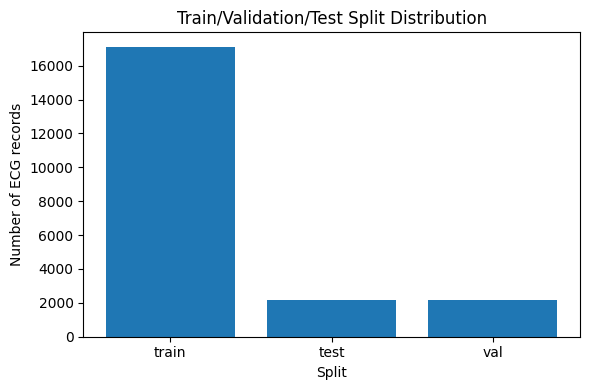

Saved figure: /kaggle/working/reports/split_distribution.png
Saved table: /kaggle/working/reports/class_counts_percentages.csv


,label,count,percentage,imbalance_ratio_vs_max
0,NORM,9528,44.461036,1.000000
1,MI,5486,25.599627,1.736785
2,STTC,5250,24.498367,1.814857
3,CD,4907,22.897807,1.941716
4,HYP,2655,12.389174,3.588701


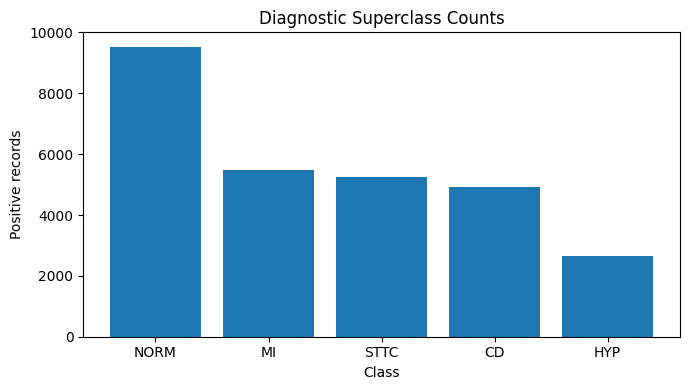

Saved figure: /kaggle/working/reports/class_counts.png


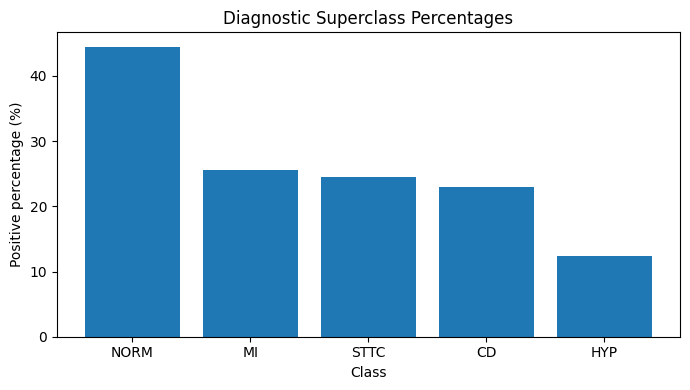

Saved figure: /kaggle/working/reports/class_percentages.png
Saved table: /kaggle/working/reports/label_cooccurrence_matrix.csv


,NORM,MI,STTC,CD,HYP
NORM,9528,1,33,415,5
MI,1,5486,1345,1801,821
STTC,33,1345,5250,1069,1514
CD,415,1801,1069,4907,789
HYP,5,821,1514,789,2655


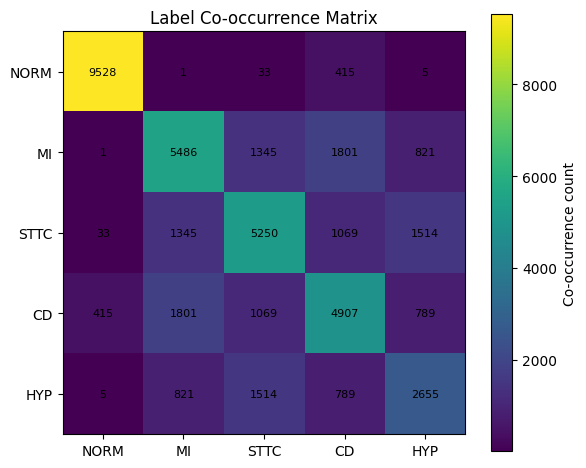

Saved figure: /kaggle/working/reports/label_cooccurrence_matrix.png
Saved table: /kaggle/working/reports/top_scp_statements.csv


,scp_code,count
0,SR,16773
1,NORM,9528
2,ABQRS,3310
3,IMI,2685
4,ASMI,2363
5,LVH,2137
6,NDT,1829
7,LAFB,1626
8,AFIB,1451
9,ISC_,1275


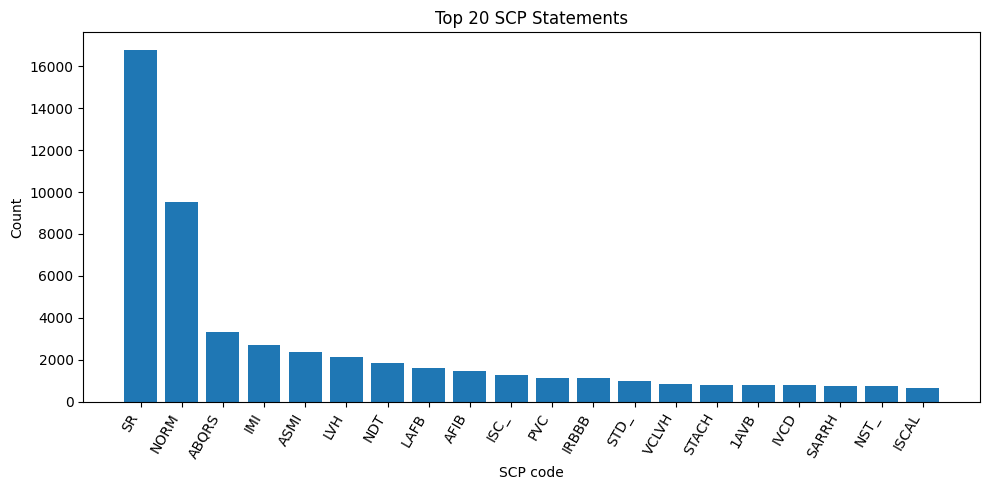

Saved figure: /kaggle/working/reports/top_scp_statements.png
Saved table: /kaggle/working/reports/afib_summary.csv


,AFIB_positive,AFIB_percentage
0,1451,6.770882


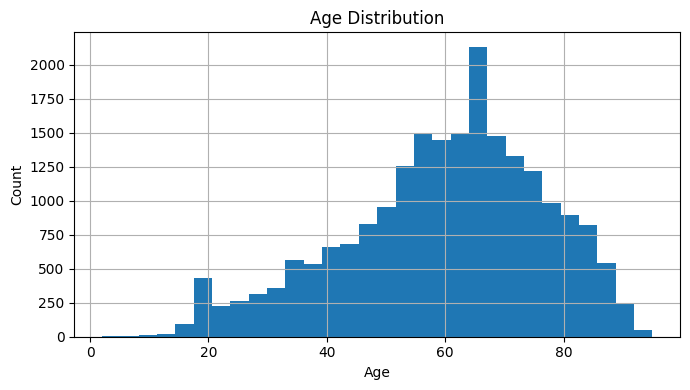

Saved figure: /kaggle/working/reports/age_distribution.png
Saved table: /kaggle/working/reports/sex_distribution.csv


,sex,count
0,0,11137
1,1,10293


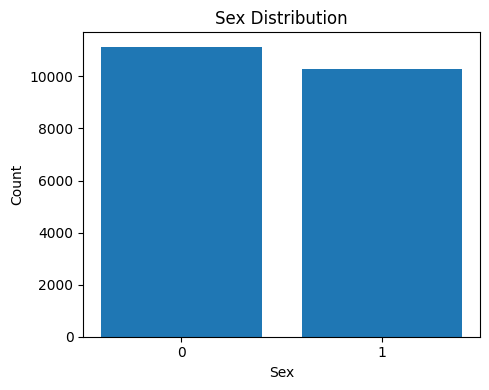

Saved figure: /kaggle/working/reports/sex_distribution.png
Saved table: /kaggle/working/reports/multi_label_cardinality.csv


,num_labels,count
0,1,16272
1,2,4079
2,3,920
3,4,159


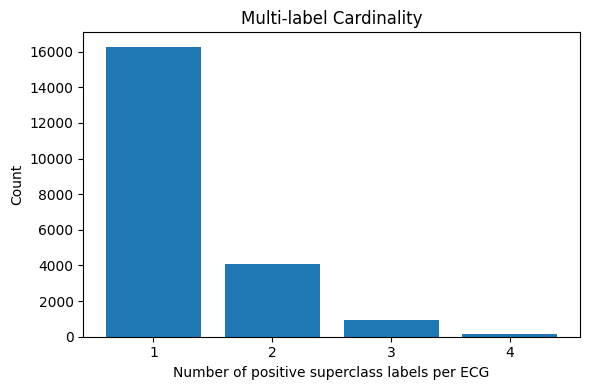

Saved figure: /kaggle/working/reports/multi_label_cardinality.png


In [88]:
def save_table(df: pd.DataFrame, name: str):
    path = REPORT_DIR / name
    df.to_csv(path, index=False)
    print("Saved table:", path)
    return path

def save_fig(path: Path):
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved figure:", path)

analysis_df = manifest.copy()

summary_rows = {
    "total_records_with_targets": len(analysis_df),
    "unique_patients": analysis_df["patient_id"].nunique() if "patient_id" in analysis_df.columns else np.nan,
    "age_mean": analysis_df["age"].mean() if "age" in analysis_df.columns else np.nan,
    "age_median": analysis_df["age"].median() if "age" in analysis_df.columns else np.nan,
    "age_missing": analysis_df["age"].isna().sum() if "age" in analysis_df.columns else np.nan,
}
dataset_summary = pd.DataFrame([summary_rows])
save_table(dataset_summary, "dataset_summary.csv")
display(dataset_summary)

split_dist = analysis_df["split"].value_counts().reset_index()
split_dist.columns = ["split", "count"]
save_table(split_dist, "split_distribution.csv")
display(split_dist)

plt.figure(figsize=(6,4))
plt.bar(split_dist["split"], split_dist["count"])
plt.title("Train/Validation/Test Split Distribution")
plt.xlabel("Split")
plt.ylabel("Number of ECG records")
save_fig(REPORT_DIR / "split_distribution.png")

class_counts = analysis_df[LABEL_NAMES].sum(axis=0).reset_index()
class_counts.columns = ["label", "count"]
class_counts["percentage"] = class_counts["count"] / len(analysis_df) * 100
positive_counts = class_counts["count"].replace(0, np.nan)
class_counts["imbalance_ratio_vs_max"] = class_counts["count"].max() / positive_counts
save_table(class_counts, "class_counts_percentages.csv")
display(class_counts)

plt.figure(figsize=(7,4))
plt.bar(class_counts["label"], class_counts["count"])
plt.title("Diagnostic Superclass Counts")
plt.xlabel("Class")
plt.ylabel("Positive records")
save_fig(REPORT_DIR / "class_counts.png")

plt.figure(figsize=(7,4))
plt.bar(class_counts["label"], class_counts["percentage"])
plt.title("Diagnostic Superclass Percentages")
plt.xlabel("Class")
plt.ylabel("Positive percentage (%)")
save_fig(REPORT_DIR / "class_percentages.png")

cooc = analysis_df[LABEL_NAMES].T.dot(analysis_df[LABEL_NAMES])
cooc_path = REPORT_DIR / "label_cooccurrence_matrix.csv"
cooc.to_csv(cooc_path)
print("Saved table:", cooc_path)
display(cooc)

plt.figure(figsize=(6,5))
plt.imshow(cooc.values)
plt.xticks(range(len(LABEL_NAMES)), LABEL_NAMES)
plt.yticks(range(len(LABEL_NAMES)), LABEL_NAMES)
plt.colorbar(label="Co-occurrence count")
plt.title("Label Co-occurrence Matrix")
for i in range(len(LABEL_NAMES)):
    for j in range(len(LABEL_NAMES)):
        plt.text(j, i, int(cooc.values[i,j]), ha="center", va="center", fontsize=8)
save_fig(REPORT_DIR / "label_cooccurrence_matrix.png")

scp_counter = Counter()
for codes in analysis_df["scp_dict"]:
    scp_counter.update(list(codes.keys()))
top_scp = pd.DataFrame(scp_counter.most_common(30), columns=["scp_code", "count"])
save_table(top_scp, "top_scp_statements.csv")
display(top_scp.head(20))

plt.figure(figsize=(10,5))
plt.bar(top_scp["scp_code"].head(20), top_scp["count"].head(20))
plt.xticks(rotation=60, ha="right")
plt.title("Top 20 SCP Statements")
plt.xlabel("SCP code")
plt.ylabel("Count")
save_fig(REPORT_DIR / "top_scp_statements.png")

afib_summary = pd.DataFrame([{
    "AFIB_positive": int(analysis_df["AFIB"].sum()) if "AFIB" in analysis_df.columns else 0,
    "AFIB_percentage": float(analysis_df["AFIB"].mean() * 100) if "AFIB" in analysis_df.columns else 0.0,
}])
save_table(afib_summary, "afib_summary.csv")
display(afib_summary)

if "age" in analysis_df.columns:
    plt.figure(figsize=(7,4))
    analysis_df["age"].dropna().hist(bins=30)
    plt.title("Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Count")
    save_fig(REPORT_DIR / "age_distribution.png")

if "sex" in analysis_df.columns:
    sex_counts = analysis_df["sex"].value_counts(dropna=False).reset_index()
    sex_counts.columns = ["sex", "count"]
    save_table(sex_counts, "sex_distribution.csv")
    display(sex_counts)
    plt.figure(figsize=(5,4))
    plt.bar(sex_counts["sex"].astype(str), sex_counts["count"])
    plt.title("Sex Distribution")
    plt.xlabel("Sex")
    plt.ylabel("Count")
    save_fig(REPORT_DIR / "sex_distribution.png")

cardinality = analysis_df[LABEL_NAMES].sum(axis=1)
cardinality_df = cardinality.value_counts().sort_index().reset_index()
cardinality_df.columns = ["num_labels", "count"]
save_table(cardinality_df, "multi_label_cardinality.csv")
display(cardinality_df)

plt.figure(figsize=(6,4))
plt.bar(cardinality_df["num_labels"].astype(str), cardinality_df["count"])
plt.title("Multi-label Cardinality")
plt.xlabel("Number of positive superclass labels per ECG")
plt.ylabel("Count")
save_fig(REPORT_DIR / "multi_label_cardinality.png")

## 8. ECG loading and preprocessing

Đọc ECG bằng `wfdb`, bandpass 0.5–40Hz, normalize từng lead.

In [87]:
LEAD_NAMES = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
SPATIAL_GRID = [
    ["I", "II", "III"],
    ["aVR", "aVL", "aVF"],
    ["V1", "V2", "V3"],
    ["V4", "V5", "V6"],
]
LEAD_TO_IDX = {lead: i for i, lead in enumerate(LEAD_NAMES)}

def read_ecg(record_path: str):
    sig, meta = wfdb.rdsamp(record_path)
    sig = np.asarray(sig, dtype=np.float32)
    return sig, meta

def pad_or_crop_signal(sig: np.ndarray, target_len: int = SIGNAL_LENGTH):
    if sig.shape[0] > target_len:
        return sig[:target_len]
    if sig.shape[0] < target_len:
        pad_len = target_len - sig.shape[0]
        pad = np.zeros((pad_len, sig.shape[1]), dtype=sig.dtype)
        return np.concatenate([sig, pad], axis=0)
    return sig

def bandpass_filter(sig: np.ndarray, fs: int = SAMPLING_RATE, low: float = 0.5, high: float = 40.0, order: int = 3):
    nyq = 0.5 * fs
    b, a = butter(order, [low / nyq, high / nyq], btype="band")
    try:
        return filtfilt(b, a, sig, axis=0).astype(np.float32)
    except Exception:
        return sig.astype(np.float32)

def normalize_per_lead(sig: np.ndarray, eps: float = 1e-6):
    mean = sig.mean(axis=0, keepdims=True)
    std = sig.std(axis=0, keepdims=True)
    return ((sig - mean) / (std + eps)).astype(np.float32)

def load_preprocessed_ecg(record_path: str):
    sig, meta = read_ecg(record_path)
    sig = pad_or_crop_signal(sig, SIGNAL_LENGTH)
    sig = bandpass_filter(sig, fs=SAMPLING_RATE)
    sig = normalize_per_lead(sig)
    return sig

sample_row = run_manifest.iloc[0]
sample_sig = load_preprocessed_ecg(sample_row["record_path"])
print("Sample ECG shape:", sample_sig.shape)
print("Record:", sample_row["record_path"])

Sample ECG shape: (1000, 12)
Record: /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records100/00000/00001_lr


## 9. Raw ECG visualization

Vẽ 12-lead waveform và layout không gian ECG.

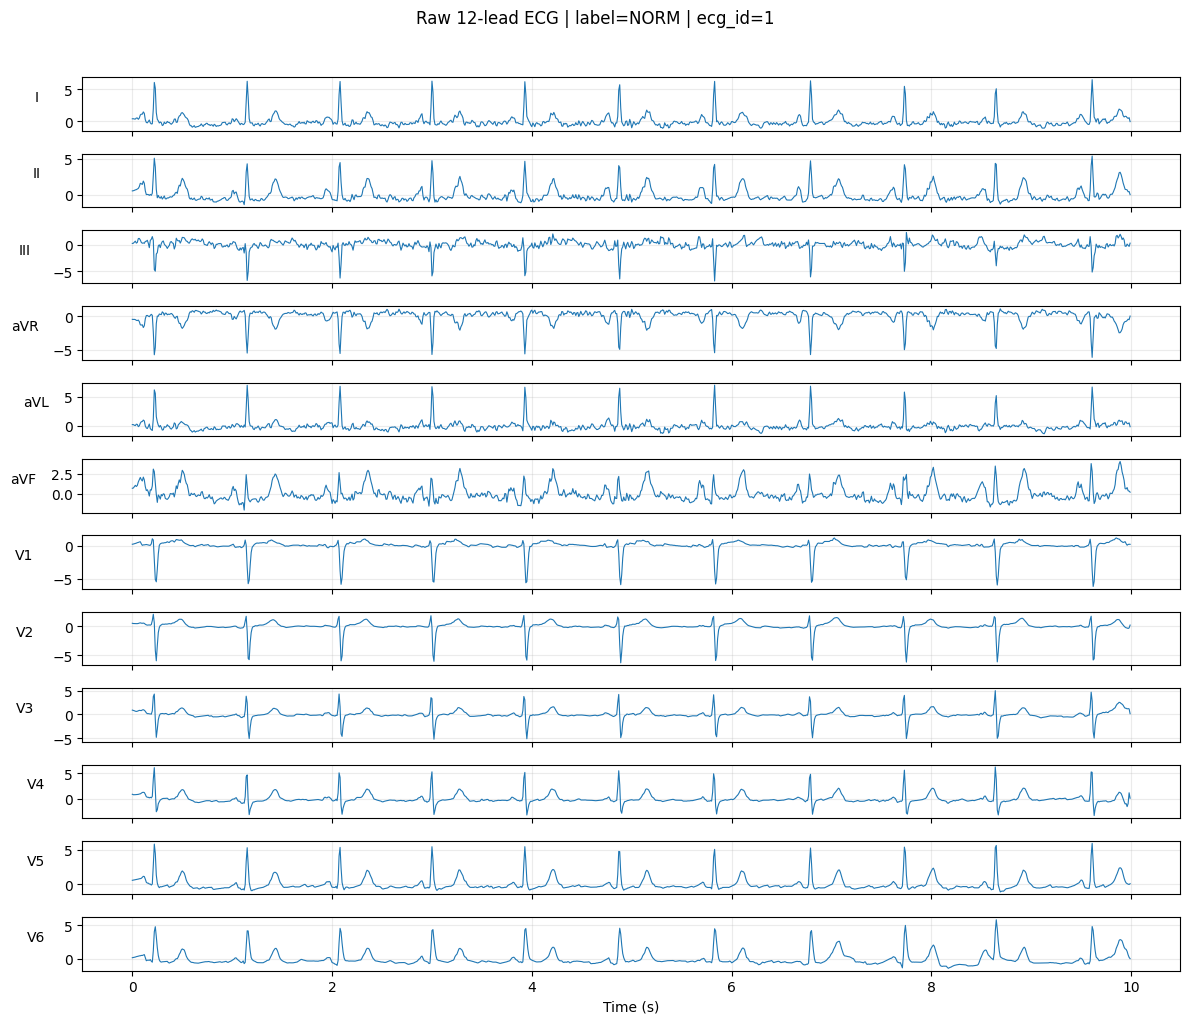

Saved: /kaggle/working/reports/raw_12lead_NORM_ecg1.png


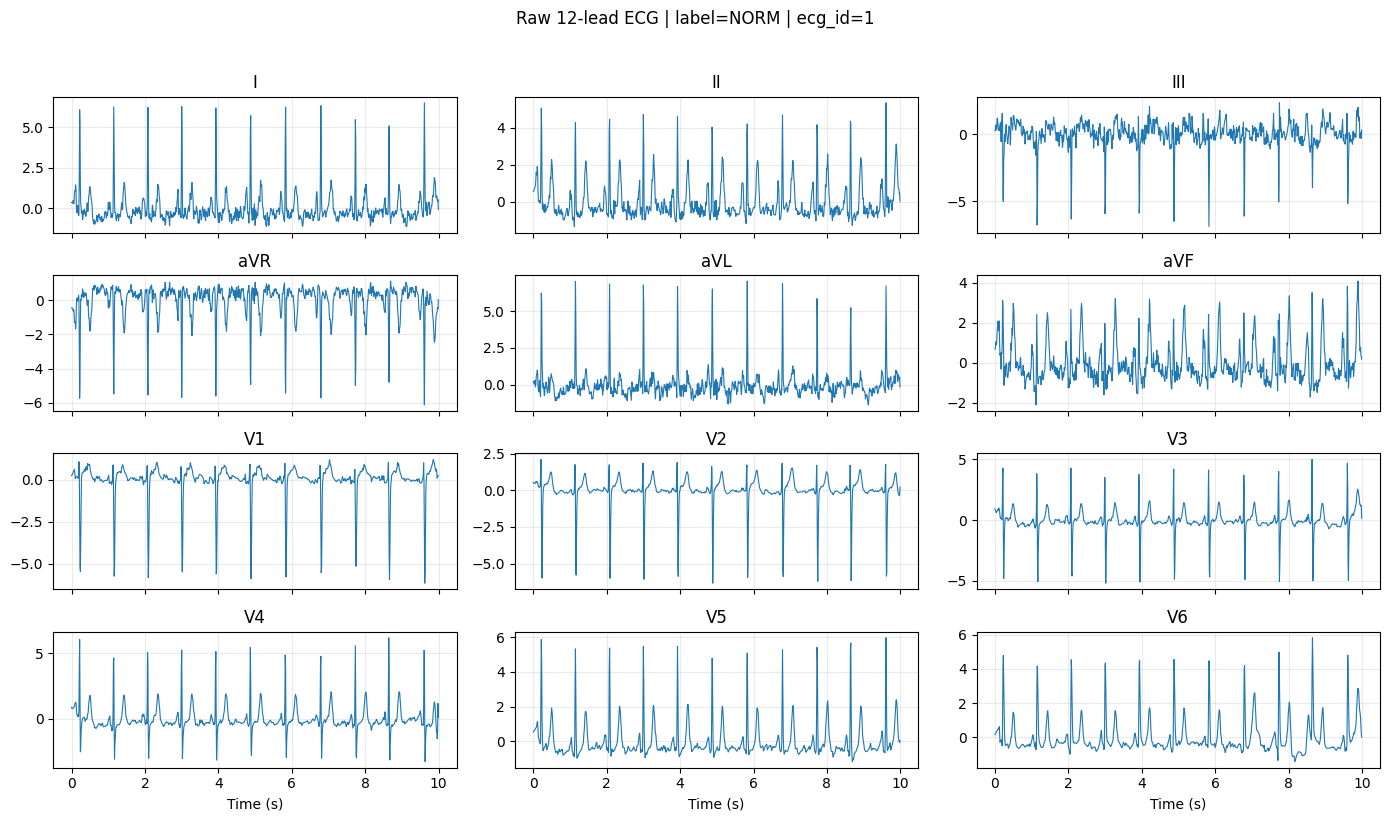

Saved: /kaggle/working/reports/spatial_12lead_NORM_ecg1.png


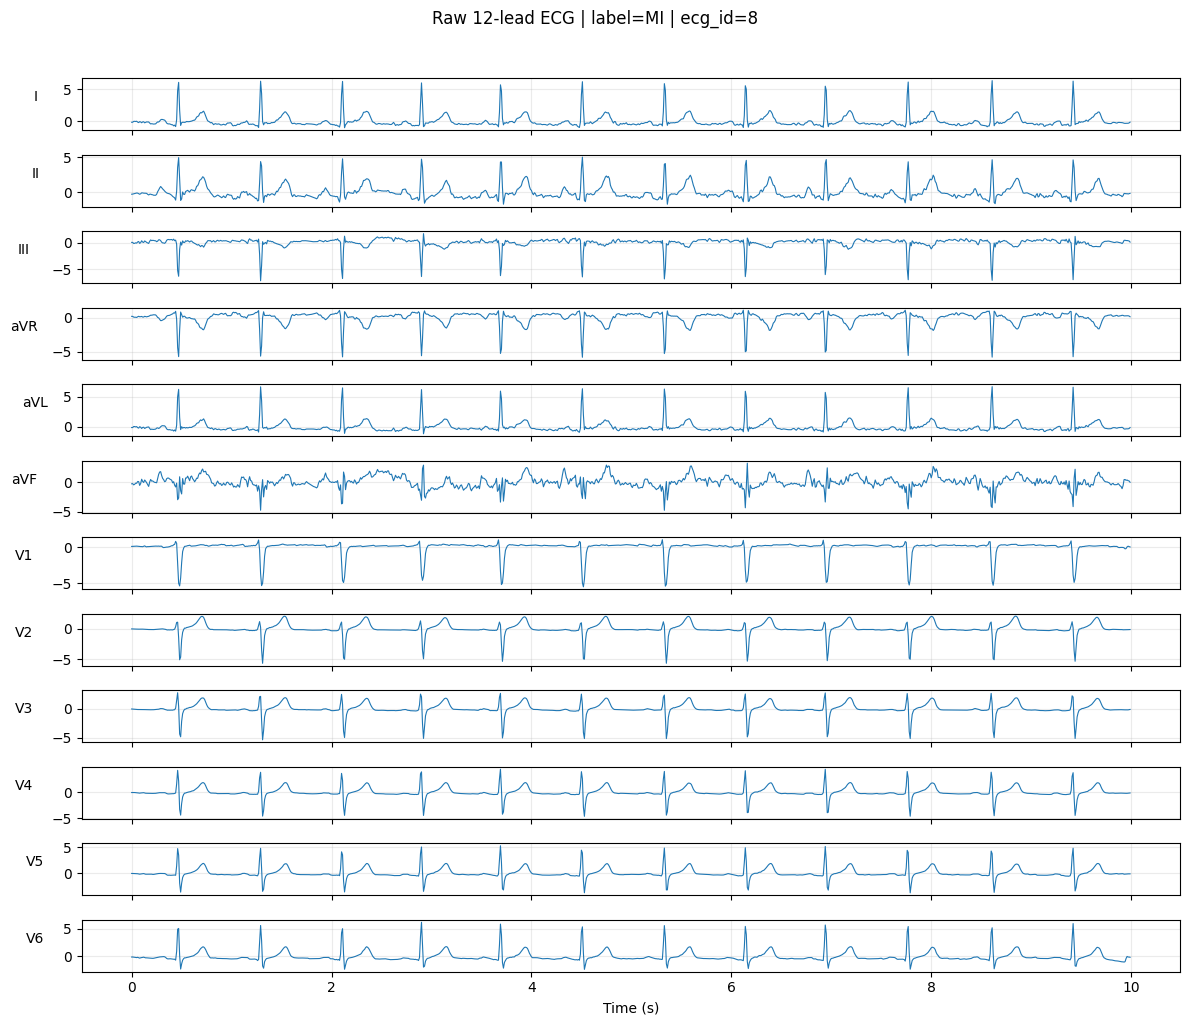

Saved: /kaggle/working/reports/raw_12lead_MI_ecg8.png


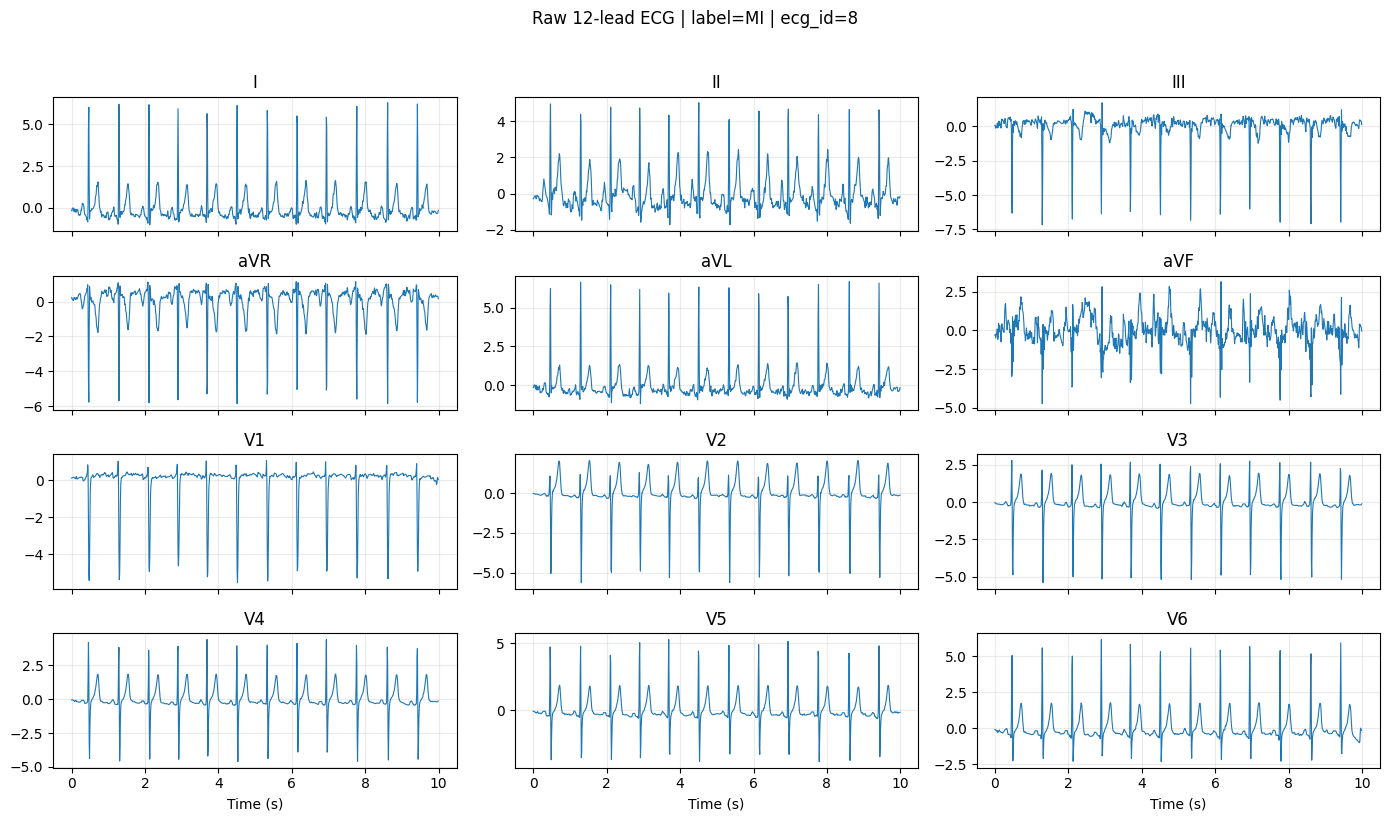

Saved: /kaggle/working/reports/spatial_12lead_MI_ecg8.png


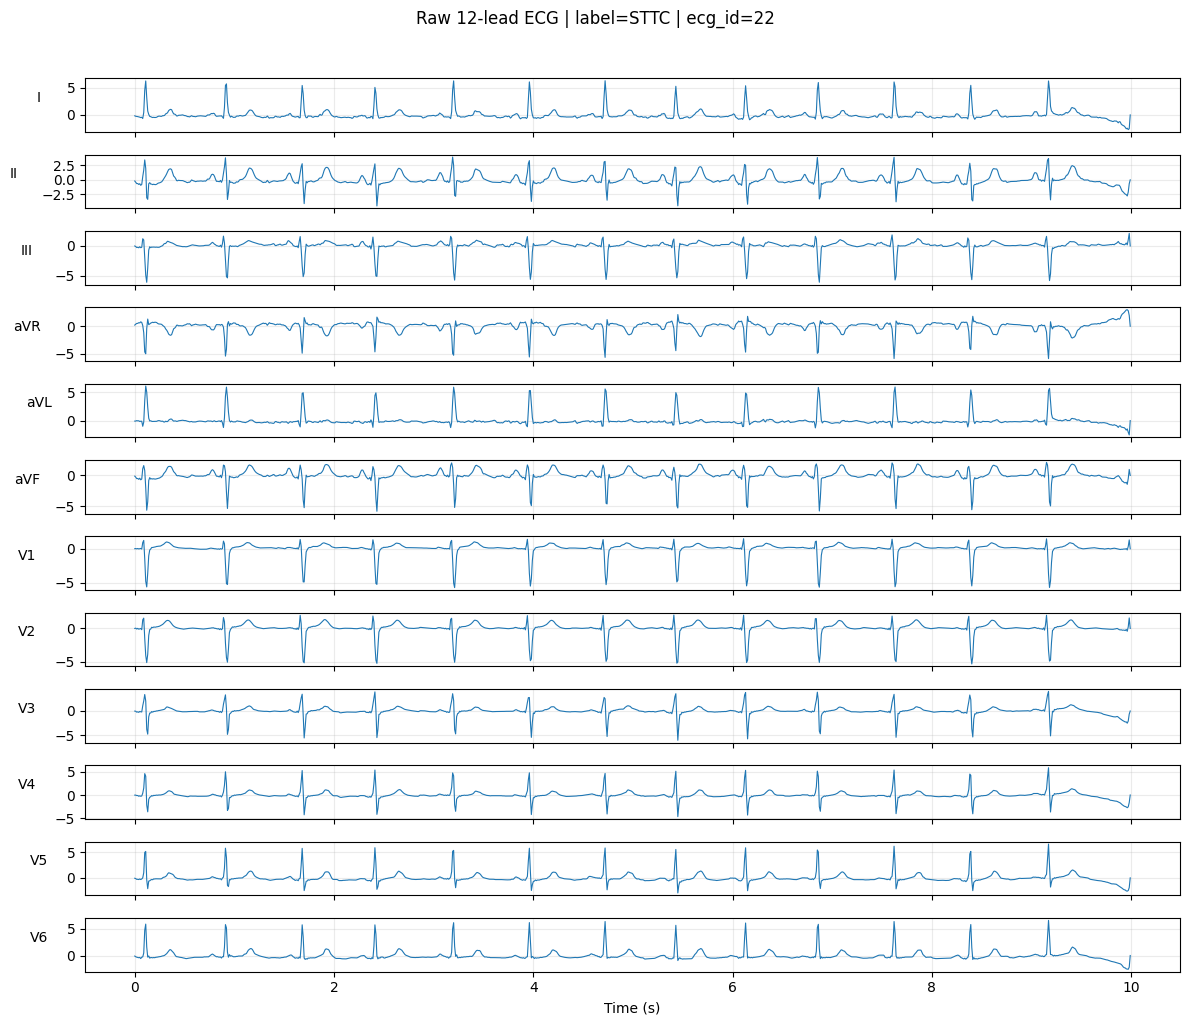

Saved: /kaggle/working/reports/raw_12lead_STTC_ecg22.png


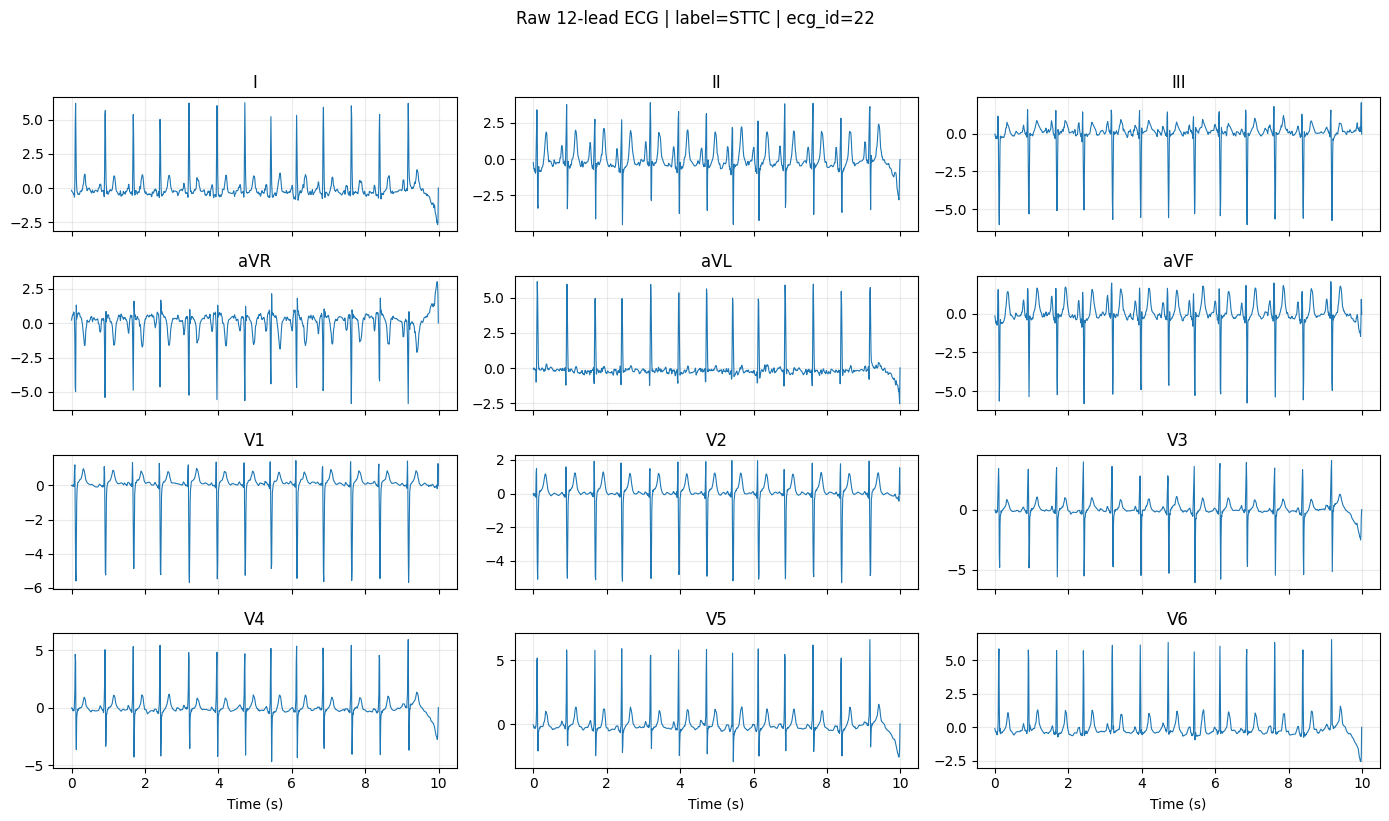

Saved: /kaggle/working/reports/spatial_12lead_STTC_ecg22.png


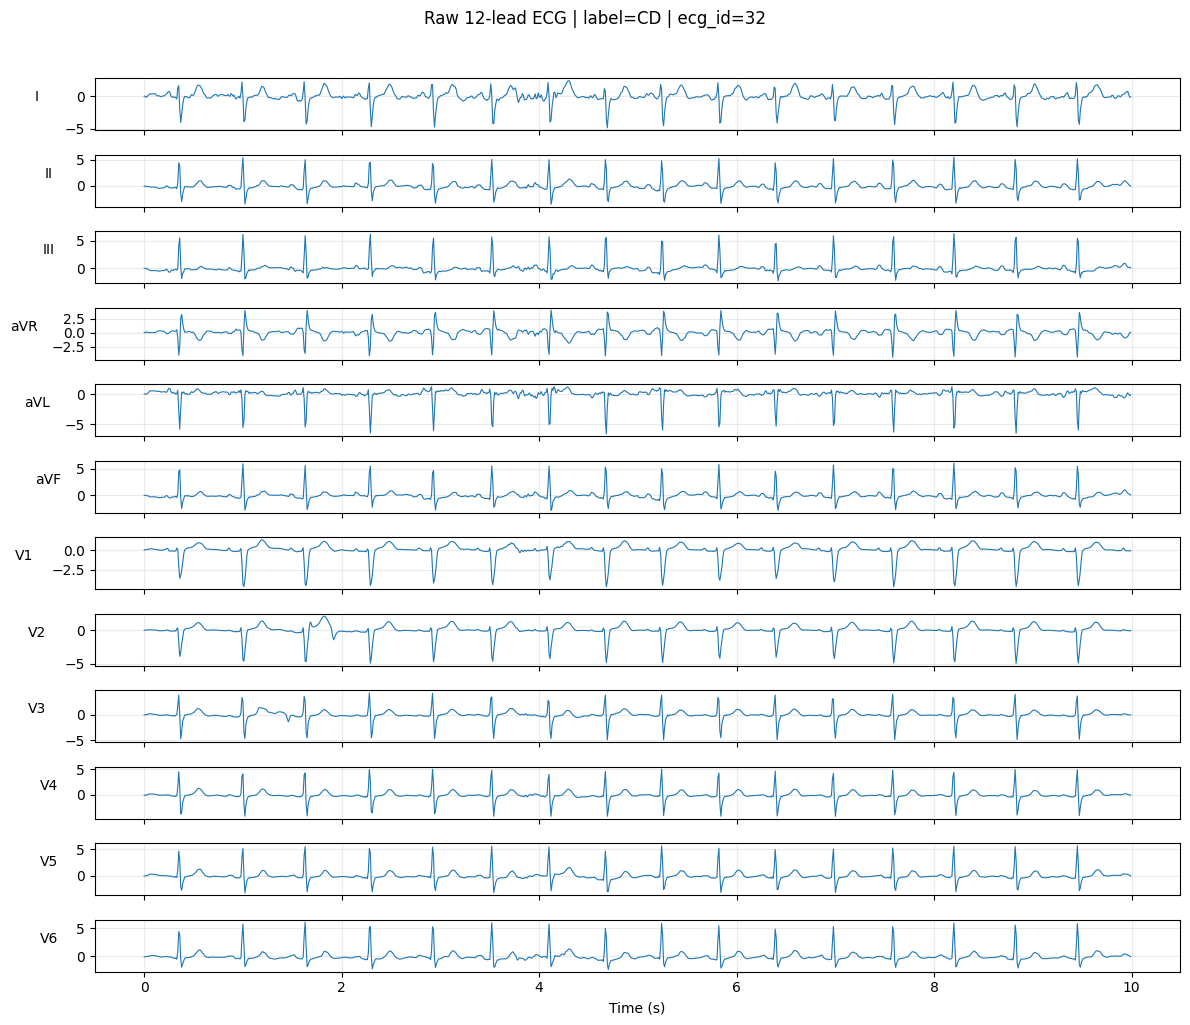

Saved: /kaggle/working/reports/raw_12lead_CD_ecg32.png


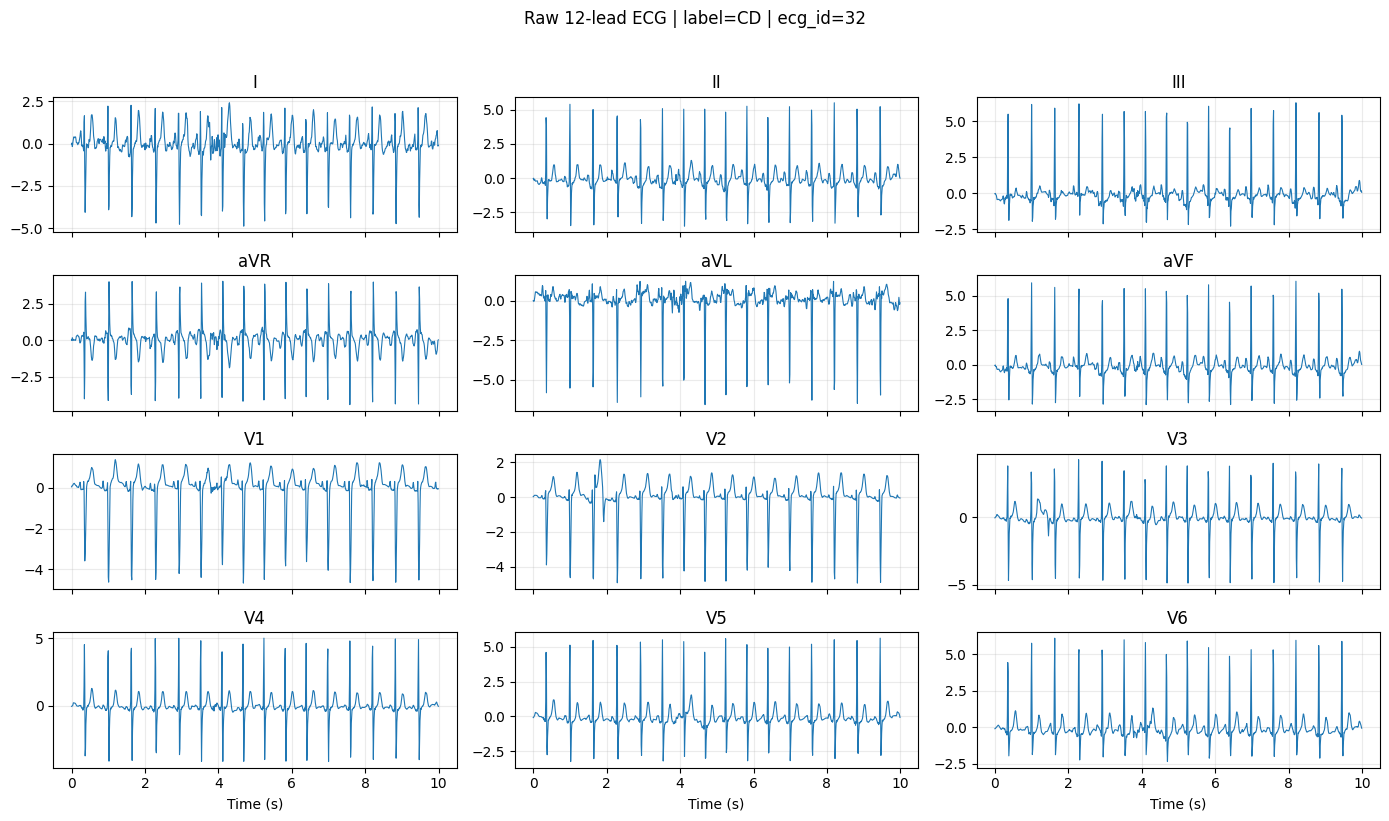

Saved: /kaggle/working/reports/spatial_12lead_CD_ecg32.png


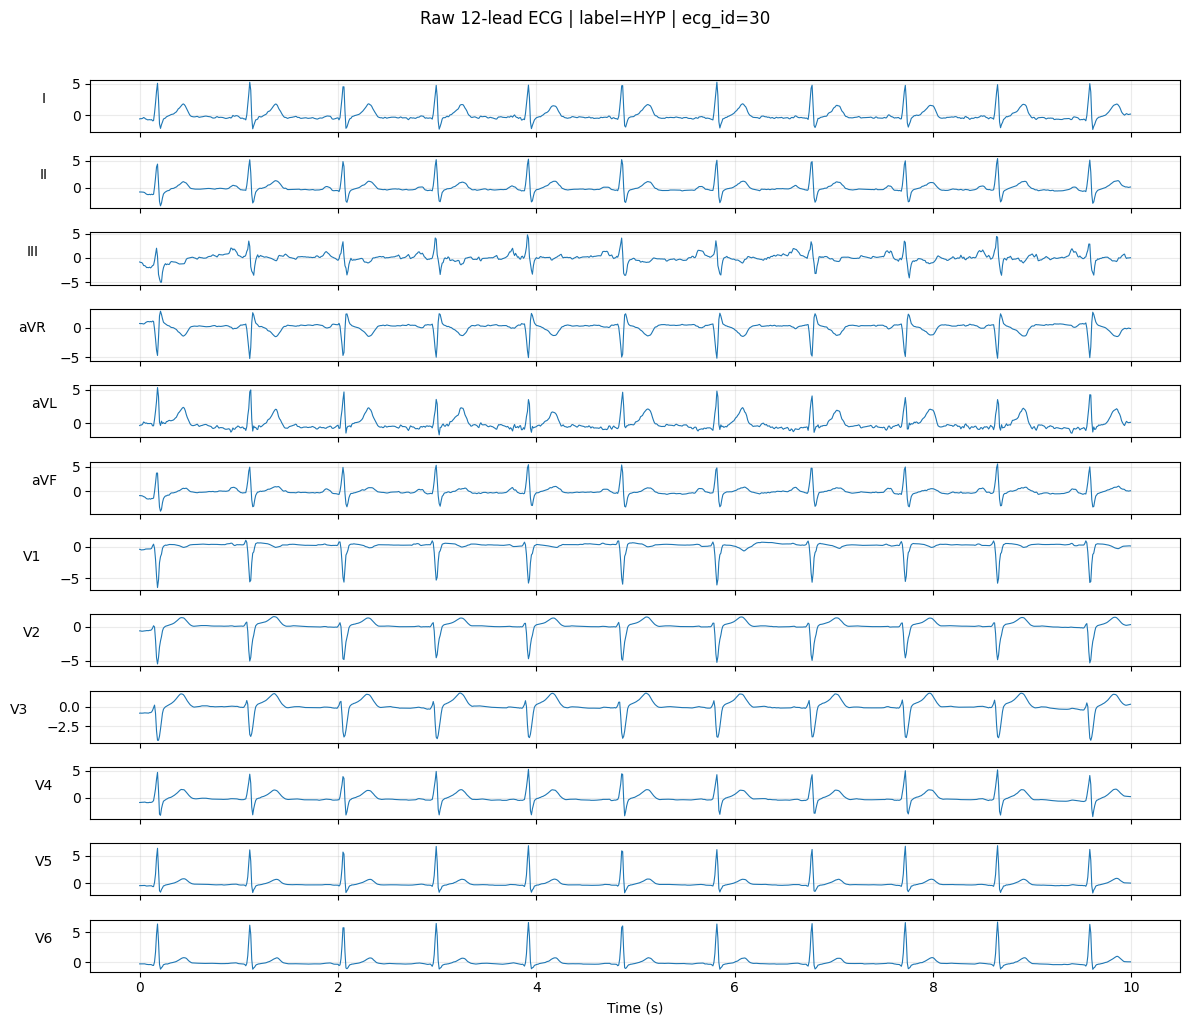

Saved: /kaggle/working/reports/raw_12lead_HYP_ecg30.png


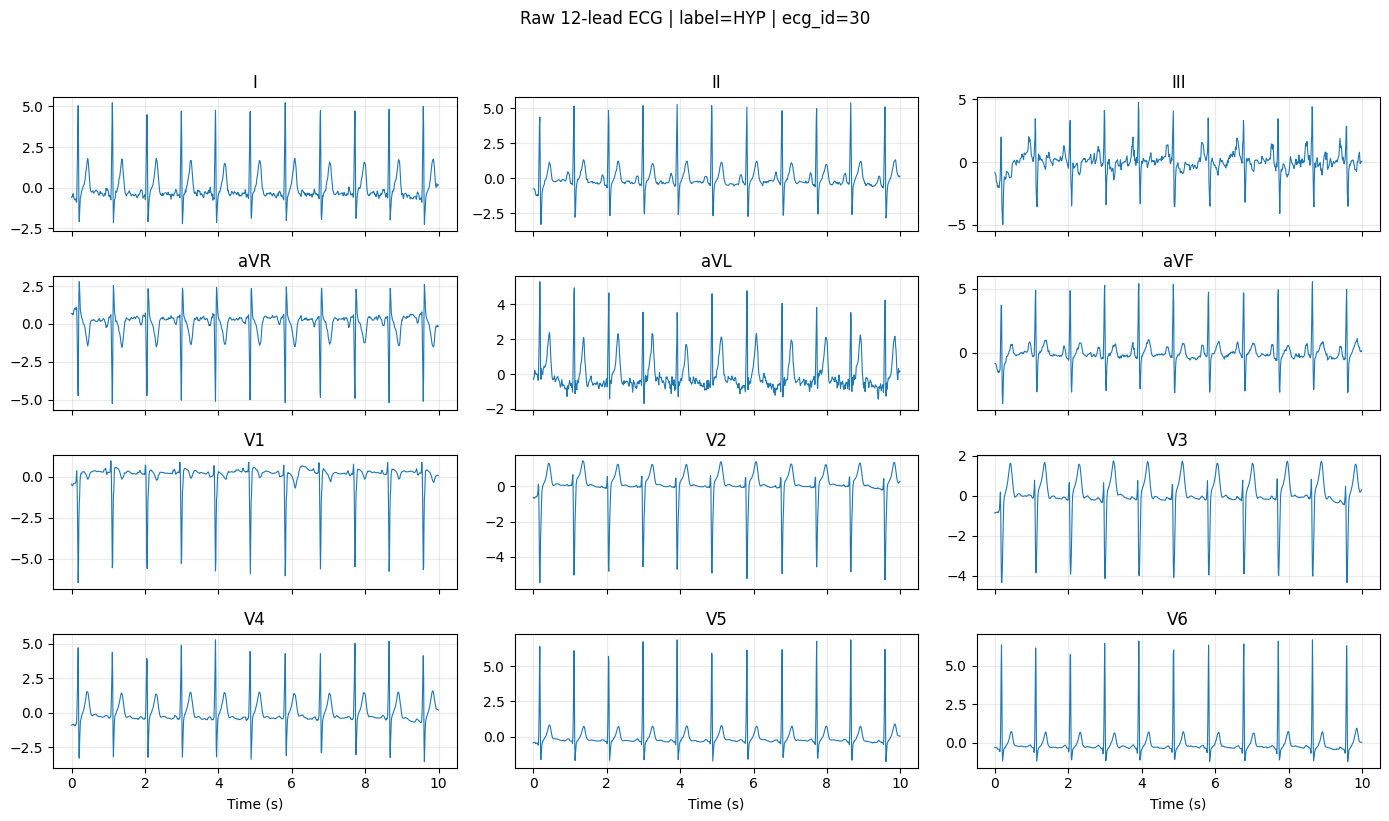

Saved: /kaggle/working/reports/spatial_12lead_HYP_ecg30.png


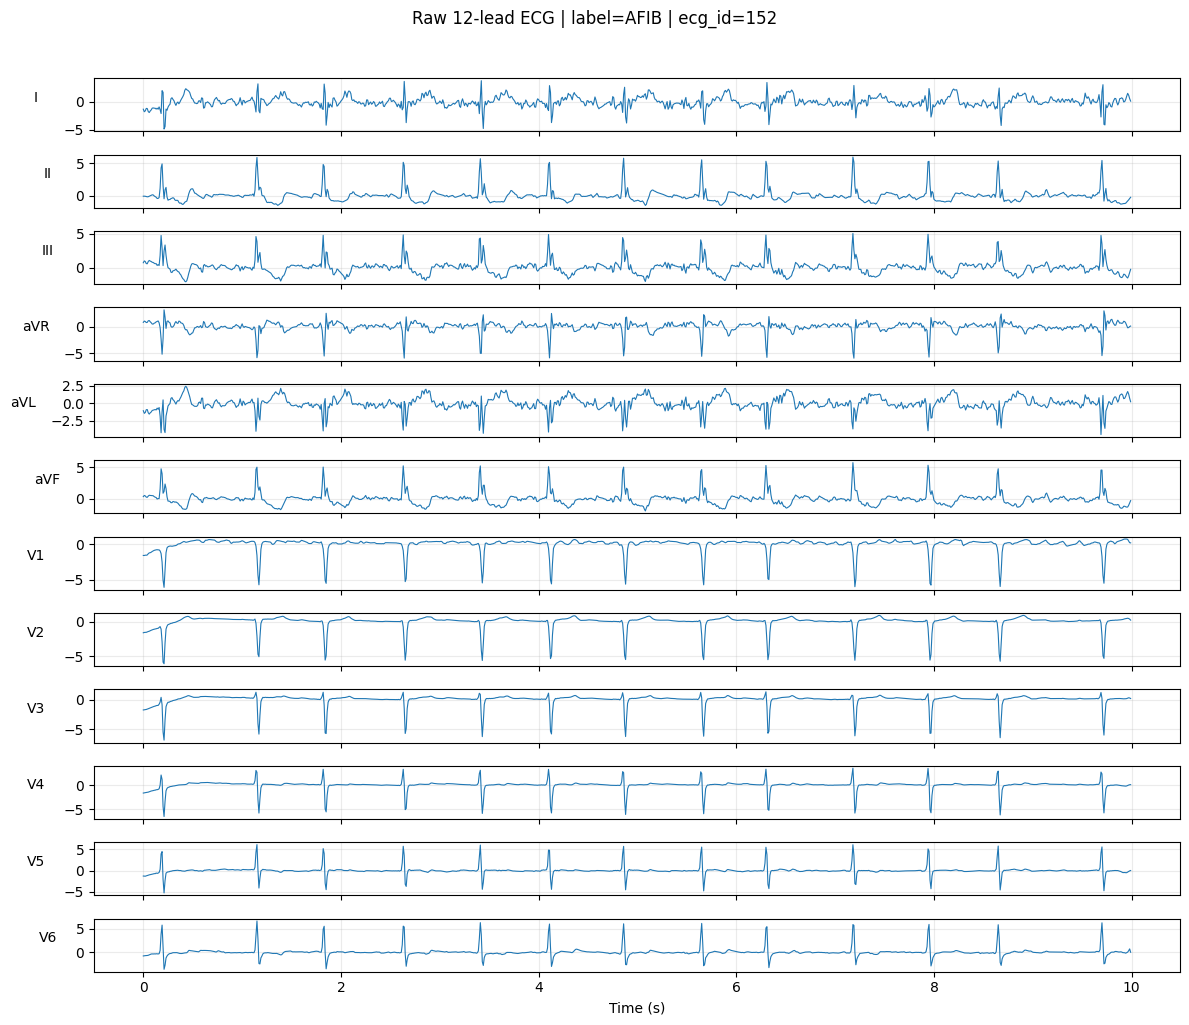

Saved: /kaggle/working/reports/raw_12lead_AFIB_ecg152.png


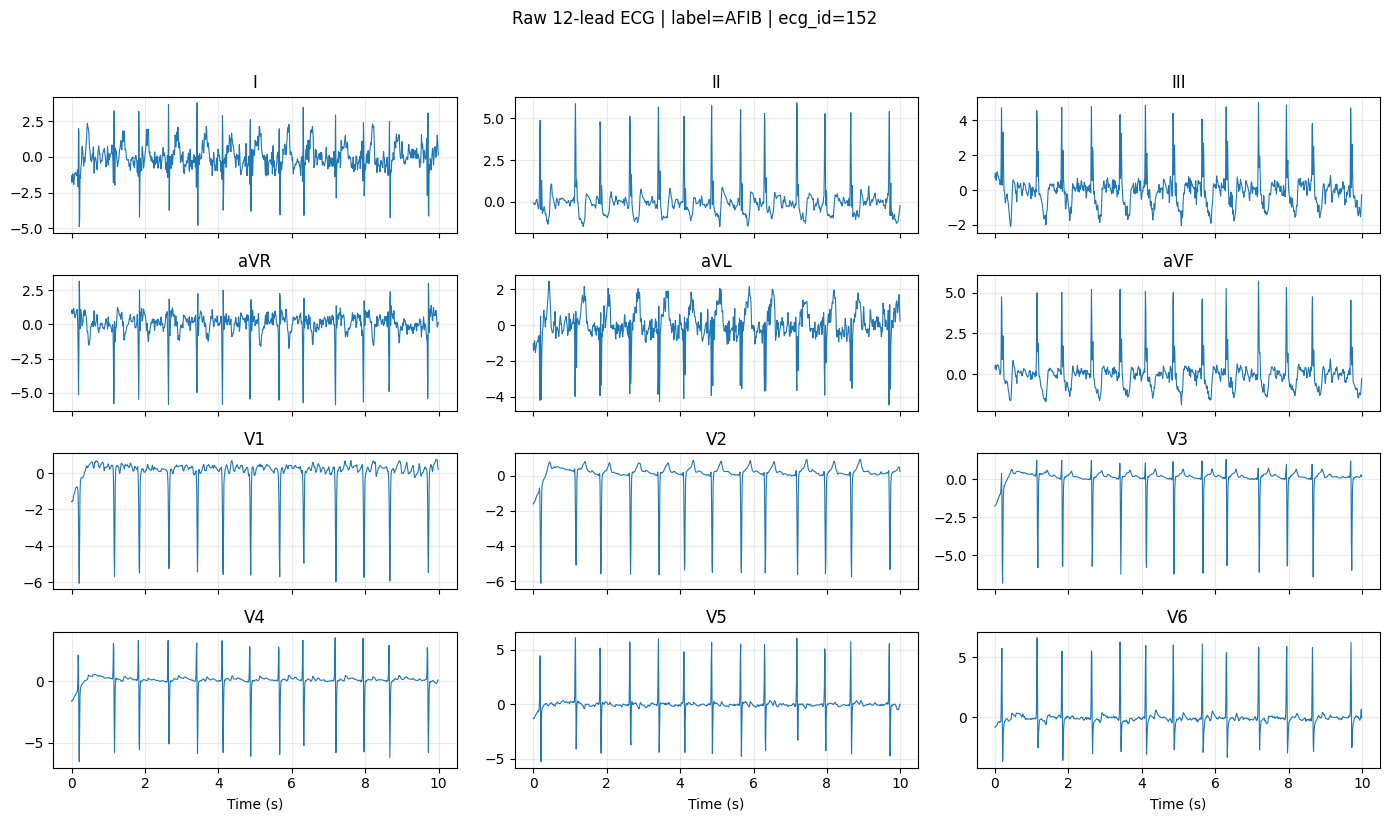

Saved: /kaggle/working/reports/spatial_12lead_AFIB_ecg152.png
Saved table: /kaggle/working/reports/representative_samples.csv


,label,ecg_id,record_path
0,NORM,1,/kaggle/input/datasets/khyeh0719/ptb-xl-datase...
1,MI,8,/kaggle/input/datasets/khyeh0719/ptb-xl-datase...
2,STTC,22,/kaggle/input/datasets/khyeh0719/ptb-xl-datase...
3,CD,32,/kaggle/input/datasets/khyeh0719/ptb-xl-datase...
4,HYP,30,/kaggle/input/datasets/khyeh0719/ptb-xl-datase...
5,AFIB,152,/kaggle/input/datasets/khyeh0719/ptb-xl-datase...


In [86]:
def find_representative_samples(df: pd.DataFrame, labels=LABEL_NAMES, include_afib=True):
    rows = []
    used = set()
    for label in labels:
        candidates = df[df[label] == 1]
        if len(candidates) > 0:
            row = candidates.iloc[0]
            if row["ecg_id"] not in used:
                rows.append((label, row))
                used.add(row["ecg_id"])
    if include_afib and "AFIB" in df.columns:
        candidates = df[df["AFIB"] == 1]
        if len(candidates) > 0:
            row = candidates.iloc[0]
            if row["ecg_id"] not in used:
                rows.append(("AFIB", row))
    return rows

def plot_raw_12lead(sig: np.ndarray, title: str, save_path: Path = None):
    t = np.arange(sig.shape[0]) / SAMPLING_RATE
    fig, axes = plt.subplots(12, 1, figsize=(12, 10), sharex=True)
    for i, lead in enumerate(LEAD_NAMES):
        axes[i].plot(t, sig[:, i], linewidth=0.8)
        axes[i].set_ylabel(lead, rotation=0, labelpad=20)
        axes[i].grid(True, alpha=0.25)
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()
    if save_path:
        print("Saved:", save_path)

def plot_spatial_12lead(sig: np.ndarray, title: str, save_path: Path = None):
    t = np.arange(sig.shape[0]) / SAMPLING_RATE
    fig, axes = plt.subplots(4, 3, figsize=(14, 8), sharex=True)
    for r in range(4):
        for c in range(3):
            lead = SPATIAL_GRID[r][c]
            idx = LEAD_TO_IDX[lead]
            ax = axes[r, c]
            ax.plot(t, sig[:, idx], linewidth=0.8)
            ax.set_title(lead)
            ax.grid(True, alpha=0.25)
    fig.suptitle(title, y=1.02)
    for ax in axes[-1, :]:
        ax.set_xlabel("Time (s)")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()
    if save_path:
        print("Saved:", save_path)

rep_samples = find_representative_samples(manifest)
rep_info = []
for label, row in rep_samples[:SAVE_EXAMPLE_LIMIT]:
    sig = load_preprocessed_ecg(row["record_path"])
    title = f"Raw 12-lead ECG | label={label} | ecg_id={row['ecg_id']}"
    plot_raw_12lead(sig, title, REPORT_DIR / f"raw_12lead_{label}_ecg{row['ecg_id']}.png")
    plot_spatial_12lead(sig, title, REPORT_DIR / f"spatial_12lead_{label}_ecg{row['ecg_id']}.png")
    rep_info.append({"label": label, "ecg_id": row["ecg_id"], "record_path": row["record_path"]})

rep_info_df = pd.DataFrame(rep_info)
save_table(rep_info_df, "representative_samples.csv")
display(rep_info_df)

## 10. Time-frequency representation functions

Tạo CWT, STFT và 12-lead grid ảnh RGB 224x224.

In [67]:
def normalize_image(x: np.ndarray, eps: float = 1e-8):
    x = np.asarray(x, dtype=np.float32)
    x = x - np.nanmin(x)
    denom = np.nanmax(x) + eps
    x = x / denom
    x = np.clip(x, 0, 1)
    return x

def cwt_scalogram_1d(x: np.ndarray):
    coeffs, freqs = pywt.cwt(x, CWT_SCALES, CWT_WAVELET, sampling_period=1.0 / SAMPLING_RATE)
    power = np.abs(coeffs)
    return normalize_image(power)

def stft_spectrogram_1d(x: np.ndarray):
    f, t, Zxx = signal.stft(
        x,
        fs=SAMPLING_RATE,
        nperseg=STFT_NPERSEG,
        noverlap=STFT_NOVERLAP,
        boundary=None
    )
    power = np.abs(Zxx)
    return normalize_image(power)

def resize_array_to_image(arr: np.ndarray, size=(IMAGE_SIZE, IMAGE_SIZE)):
    img = Image.fromarray((normalize_image(arr) * 255).astype(np.uint8))
    img = img.resize(size, resample=Image.BILINEAR)
    return np.asarray(img, dtype=np.float32) / 255.0

def make_lead_grid_image(sig: np.ndarray, representation: str = "cwt", image_size: int = IMAGE_SIZE):
    """
    Create a 4x3 spatial grid image from 12-lead ECG.
    representation: "cwt" or "stft".
    Returns uint8 RGB image with shape [image_size, image_size, 3].
    """
    cell_h = image_size // 4
    cell_w = image_size // 3
    grid = np.zeros((cell_h * 4, cell_w * 3), dtype=np.float32)

    for r in range(4):
        for c in range(3):
            lead = SPATIAL_GRID[r][c]
            idx = LEAD_TO_IDX[lead]
            x = sig[:, idx]
            if representation == "cwt":
                arr = cwt_scalogram_1d(x)
            elif representation == "stft":
                arr = stft_spectrogram_1d(x)
            else:
                raise ValueError("representation must be 'cwt' or 'stft'")

            arr_resized = resize_array_to_image(arr, size=(cell_w, cell_h))
            grid[r*cell_h:(r+1)*cell_h, c*cell_w:(c+1)*cell_w] = arr_resized

    img = Image.fromarray((normalize_image(grid) * 255).astype(np.uint8)).resize((image_size, image_size))
    rgb = np.stack([np.asarray(img)] * 3, axis=-1).astype(np.uint8)
    return rgb

def save_grid_image(sig: np.ndarray, out_path: Path, representation: str):
    img = make_lead_grid_image(sig, representation=representation)
    Image.fromarray(img).save(out_path)
    return out_path

sample_sig = load_preprocessed_ecg(run_manifest.iloc[0]["record_path"])
cwt_img = make_lead_grid_image(sample_sig, "cwt")
stft_img = make_lead_grid_image(sample_sig, "stft")
print("CWT grid shape:", cwt_img.shape, "STFT grid shape:", stft_img.shape)

CWT grid shape: (224, 224, 3) STFT grid shape: (224, 224, 3)


## 11. Visualize CWT/STFT examples

Vẽ CWT/STFT cho lead II và grid 12-lead.

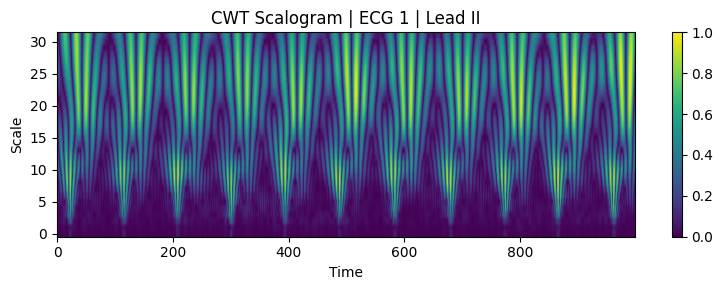

Saved figure: /kaggle/working/reports/ecg1_cwt_lead_II.png


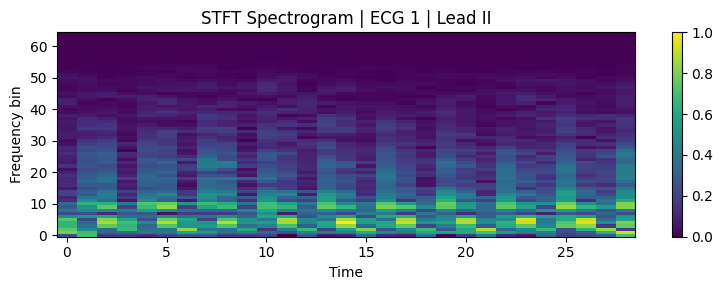

Saved figure: /kaggle/working/reports/ecg1_stft_lead_II.png


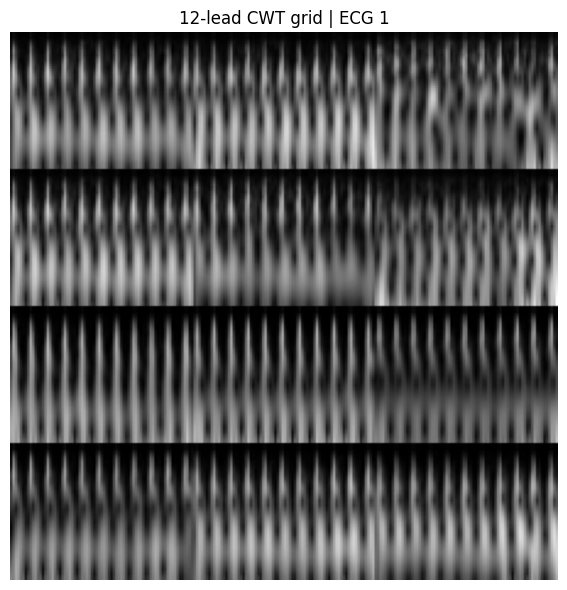

Saved figure: /kaggle/working/reports/ecg1_cwt_grid.png


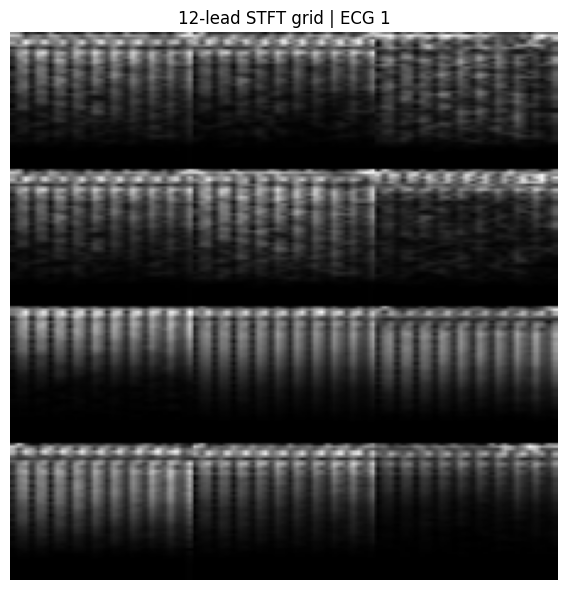

Saved figure: /kaggle/working/reports/ecg1_stft_grid.png


In [68]:
def plot_single_lead_tf(sig: np.ndarray, lead: str, ecg_id, save_prefix: str):
    idx = LEAD_TO_IDX[lead]
    x = sig[:, idx]
    cwt = cwt_scalogram_1d(x)
    stft = stft_spectrogram_1d(x)

    plt.figure(figsize=(8, 3))
    plt.imshow(cwt, aspect="auto", origin="lower")
    plt.title(f"CWT Scalogram | ECG {ecg_id} | Lead {lead}")
    plt.xlabel("Time")
    plt.ylabel("Scale")
    plt.colorbar()
    save_fig(REPORT_DIR / f"{save_prefix}_cwt_lead_{lead}.png")

    plt.figure(figsize=(8, 3))
    plt.imshow(stft, aspect="auto", origin="lower")
    plt.title(f"STFT Spectrogram | ECG {ecg_id} | Lead {lead}")
    plt.xlabel("Time")
    plt.ylabel("Frequency bin")
    plt.colorbar()
    save_fig(REPORT_DIR / f"{save_prefix}_stft_lead_{lead}.png")

def plot_grid_image(img: np.ndarray, title: str, save_path: Path):
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(title)
    save_fig(save_path)

example_row = run_manifest.iloc[0]
example_sig = load_preprocessed_ecg(example_row["record_path"])
example_ecg_id = example_row["ecg_id"]

plot_single_lead_tf(example_sig, lead="II", ecg_id=example_ecg_id, save_prefix=f"ecg{example_ecg_id}")
plot_grid_image(make_lead_grid_image(example_sig, "cwt"), f"12-lead CWT grid | ECG {example_ecg_id}", REPORT_DIR / f"ecg{example_ecg_id}_cwt_grid.png")
plot_grid_image(make_lead_grid_image(example_sig, "stft"), f"12-lead STFT grid | ECG {example_ecg_id}", REPORT_DIR / f"ecg{example_ecg_id}_stft_grid.png")

## 12. Build CWT/STFT image dataset

Generate image dataset vào `/kaggle/working/data/cwt_grid` và `/kaggle/working/data/stft_grid`.

In [69]:
def image_path_for(row, representation: str):
    out_dir = CWT_DIR if representation == "cwt" else STFT_DIR
    return out_dir / f"ecg_{int(row['ecg_id'])}_{representation}.png"

def generate_images_for_manifest(df: pd.DataFrame, representation: str):
    out_paths = []
    errors = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc=f"Generating {representation} grid images"):
        out_path = image_path_for(row, representation)
        out_paths.append(str(out_path))
        if SKIP_EXISTING_IMAGES and out_path.exists():
            continue
        try:
            sig = load_preprocessed_ecg(row["record_path"])
            save_grid_image(sig, out_path, representation)
        except Exception as e:
            errors.append({"ecg_id": row["ecg_id"], "representation": representation, "error": str(e)})
    return out_paths, errors

cwt_paths, cwt_errors = generate_images_for_manifest(run_manifest, "cwt")
stft_paths, stft_errors = generate_images_for_manifest(run_manifest, "stft")

manifest_images = run_manifest.copy()
manifest_images["cwt_path"] = cwt_paths
manifest_images["stft_path"] = stft_paths

manifest_images_path = MANIFEST_DIR / f"manifest_images_{RUN_MODE}.csv"
manifest_images.to_csv(manifest_images_path, index=False)

errors_df = pd.DataFrame(cwt_errors + stft_errors)
errors_path = REPORT_DIR / "image_generation_errors.csv"
errors_df.to_csv(errors_path, index=False)

print("Saved image manifest:", manifest_images_path)
print("Image generation errors:", len(errors_df))
display(manifest_images[["ecg_id", "split", "cwt_path", "stft_path"] + LABEL_NAMES].head())
if len(errors_df) > 0:
    display(errors_df.head())

Generating cwt grid images:   0%|          | 0/21430 [00:00<?, ?it/s]

Generating stft grid images:   0%|          | 0/21430 [00:00<?, ?it/s]

Saved image manifest: /kaggle/working/manifests/manifest_images_full.csv
Image generation errors: 0


,ecg_id,split,cwt_path,stft_path,NORM,MI,STTC,CD,HYP
0,1,train,/kaggle/working/data/cwt_grid/ecg_1_cwt.png,/kaggle/working/data/stft_grid/ecg_1_stft.png,1,0,0,0,0
1,2,train,/kaggle/working/data/cwt_grid/ecg_2_cwt.png,/kaggle/working/data/stft_grid/ecg_2_stft.png,1,0,0,0,0
2,3,train,/kaggle/working/data/cwt_grid/ecg_3_cwt.png,/kaggle/working/data/stft_grid/ecg_3_stft.png,1,0,0,0,0
3,4,train,/kaggle/working/data/cwt_grid/ecg_4_cwt.png,/kaggle/working/data/stft_grid/ecg_4_stft.png,1,0,0,0,0
4,5,train,/kaggle/working/data/cwt_grid/ecg_5_cwt.png,/kaggle/working/data/stft_grid/ecg_5_stft.png,1,0,0,0,0


## 13. PyTorch Dataset and DataLoaders

Dataset đọc ảnh CWT/STFT và labels.

In [70]:
class ECGImageDataset(Dataset):
    def __init__(self, df: pd.DataFrame, image_col: str, label_names, transform=None):
        self.df = df.reset_index(drop=True).copy()
        self.image_col = image_col
        self.label_names = label_names
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = Path(row[self.image_col])
        try:
            img = Image.open(img_path).convert("RGB")
        except Exception:
            img = Image.fromarray(np.zeros((IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8))
        if self.transform:
            img = self.transform(img)
        labels = torch.tensor(row[self.label_names].values.astype(np.float32))
        return {
            "image": img,
            "labels": labels,
            "ecg_id": int(row["ecg_id"]),
            "image_path": str(img_path),
        }

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomApply([transforms.RandomRotation(degrees=3)], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

def make_loaders(manifest_images: pd.DataFrame, image_col: str = "cwt_path", batch_size: int = BATCH_SIZE):
    train_df = manifest_images[manifest_images["split"] == "train"].copy()
    val_df = manifest_images[manifest_images["split"] == "val"].copy()
    test_df = manifest_images[manifest_images["split"] == "test"].copy()

    train_ds = ECGImageDataset(
        train_df,
        image_col=image_col,
        label_names=LABEL_NAMES,
        transform=train_transform
    )

    val_ds = ECGImageDataset(
        val_df,
        image_col=image_col,
        label_names=LABEL_NAMES,
        transform=eval_transform
    )

    test_ds = ECGImageDataset(
        test_df,
        image_col=image_col,
        label_names=LABEL_NAMES,
        transform=eval_transform
    )

    loader_kwargs = {
        "batch_size": batch_size,
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY,
    }

    # Only use multiprocessing-specific options when num_workers > 0
    if NUM_WORKERS > 0:
        loader_kwargs["persistent_workers"] = True
        loader_kwargs["prefetch_factor"] = 2

    train_loader = DataLoader(
        train_ds,
        shuffle=True,
        **loader_kwargs
    )

    val_loader = DataLoader(
        val_ds,
        shuffle=False,
        **loader_kwargs
    )

    test_loader = DataLoader(
        test_ds,
        shuffle=False,
        **loader_kwargs
    )

    return train_loader, val_loader, test_loader, train_df, val_df, test_df


train_loader, val_loader, test_loader, train_df, val_df, test_df = make_loaders(
    manifest_images,
    image_col="cwt_path",
    batch_size=BATCH_SIZE
)
print("Train/Val/Test sizes:", len(train_df), len(val_df), len(test_df))
batch = next(iter(train_loader))
print("Batch image:", batch["image"].shape)
print("Batch labels:", batch["labels"].shape)

Train/Val/Test sizes: 17111 2156 2163
Batch image: torch.Size([16, 3, 224, 224])
Batch labels: torch.Size([16, 5])


## 14. Model: ConvNeXt-Tiny multi-label classifier

Output là 5 logits cho `NORM, MI, STTC, CD, HYP`.

In [71]:
def list_available_convnextv2_models():
    try:
        models = timm.list_models("convnextv2*")
        print("Available ConvNeXtV2 models in timm:")
        for m in models:
            print(" -", m)
        return models
    except Exception as e:
        print("Could not list ConvNeXtV2 models:", e)
        return []


def resolve_convnextv2_name(backbone: str = "convnextv2_base"):
    """
    Select a ConvNeXtV2 model name available in the installed timm version.
    Preference:
    - base/large with ImageNet-22k fine-tuning if available
    - base/large with ImageNet-1k fine-tuning
    - tiny fallback
    """
    available = timm.list_models("convnextv2*")

    candidates_by_backbone = {
        "convnextv2_tiny": [
            "convnextv2_tiny.fcmae_ft_in22k_in1k",
            "convnextv2_tiny.fcmae_ft_in1k",
            "convnextv2_tiny",
        ],
        "convnextv2_base": [
            "convnextv2_base.fcmae_ft_in22k_in1k",
            "convnextv2_base.fcmae_ft_in1k",
            "convnextv2_base",
        ],
        "convnextv2_large": [
            "convnextv2_large.fcmae_ft_in22k_in1k",
            "convnextv2_large.fcmae_ft_in1k",
            "convnextv2_large",
        ],
        "convnextv2_huge": [
            "convnextv2_huge.fcmae_ft_in22k_in1k",
            "convnextv2_huge.fcmae_ft_in1k",
            "convnextv2_huge",
        ],
    }

    candidates = candidates_by_backbone.get(backbone, candidates_by_backbone["convnextv2_base"])

    for name in candidates:
        if name in available:
            return name

    print("Requested ConvNeXtV2 variant not found. Available models:")
    for m in available:
        print(" -", m)

    # safe fallback
    for fallback in [
        "convnextv2_tiny.fcmae_ft_in1k",
        "convnextv2_tiny",
        "convnextv2_base",
    ]:
        if fallback in available:
            print("Using fallback:", fallback)
            return fallback

    raise ValueError("No ConvNeXtV2 model found in timm. Please check timm installation.")


def build_convnextv2(num_classes: int, pretrained: bool = PRETRAINED, backbone: str = MODEL_BACKBONE):
    model_name = resolve_convnextv2_name(backbone)

    try:
        model = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=num_classes,
            in_chans=3
        )
        print(f"Loaded {model_name} | pretrained={pretrained} | num_classes={num_classes}")
    except Exception as e:
        print("Could not load pretrained ConvNeXtV2 weights.")
        print("Error:", e)
        print("Falling back to pretrained=False.")
        model = timm.create_model(
            model_name,
            pretrained=False,
            num_classes=num_classes,
            in_chans=3
        )
        print(f"Loaded {model_name} | pretrained=False | num_classes={num_classes}")

    return model


# Check model
available_convnextv2 = list_available_convnextv2_models()
model = build_convnextv2(num_classes=len(LABEL_NAMES), pretrained=PRETRAINED).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Model:", MODEL_BACKBONE)
print("Total parameters:", f"{n_params:,}")
print("Trainable parameters:", f"{n_trainable:,}")

Available ConvNeXtV2 models in timm:
 - convnextv2_atto
 - convnextv2_base
 - convnextv2_femto
 - convnextv2_huge
 - convnextv2_large
 - convnextv2_nano
 - convnextv2_pico
 - convnextv2_small
 - convnextv2_tiny


model.safetensors:   0%|          | 0.00/355M [00:00<?, ?B/s]

Loaded convnextv2_base | pretrained=True | num_classes=5
Model: convnextv2_base
Total parameters: 87,697,925
Trainable parameters: 87,697,925


## 15. Metrics functions

Safe metrics cho debug/full mode.

In [72]:
def sigmoid_np(x):
    return 1 / (1 + np.exp(-x))

def safe_binary_auc(y_true, y_score):
    try:
        if len(np.unique(y_true)) < 2:
            return np.nan
        return roc_auc_score(y_true, y_score)
    except Exception:
        return np.nan

def safe_binary_ap(y_true, y_score):
    try:
        if np.sum(y_true) == 0:
            return np.nan
        return average_precision_score(y_true, y_score)
    except Exception:
        return np.nan

def compute_metrics(y_true: np.ndarray, y_prob: np.ndarray, threshold=THRESHOLD_DEFAULT, label_names=LABEL_NAMES):
    y_pred = (y_prob >= threshold).astype(int)
    per_rows = []
    for i, label in enumerate(label_names):
        yt = y_true[:, i]
        yp = y_prob[:, i]
        yd = y_pred[:, i]
        per_rows.append({
            "label": label,
            "support": int(yt.sum()),
            "auroc": safe_binary_auc(yt, yp),
            "auprc": safe_binary_ap(yt, yp),
            "f1": f1_score(yt, yd, zero_division=0),
            "precision": precision_score(yt, yd, zero_division=0),
            "recall_sensitivity": recall_score(yt, yd, zero_division=0),
            "specificity": recall_score(1 - yt, 1 - yd, zero_division=0),
        })

    per_df = pd.DataFrame(per_rows)

    metrics = {
        "macro_auroc": float(np.nanmean(per_df["auroc"].values)),
        "macro_auprc": float(np.nanmean(per_df["auprc"].values)),
        "macro_f1": float(np.nanmean(per_df["f1"].values)),
        "macro_precision": float(np.nanmean(per_df["precision"].values)),
        "macro_recall": float(np.nanmean(per_df["recall_sensitivity"].values)),
    }

    try:
        metrics["micro_auroc"] = roc_auc_score(y_true.ravel(), y_prob.ravel())
    except Exception:
        metrics["micro_auroc"] = np.nan

    try:
        metrics["micro_auprc"] = average_precision_score(y_true.ravel(), y_prob.ravel())
    except Exception:
        metrics["micro_auprc"] = np.nan

    try:
        metrics["micro_f1"] = f1_score(y_true.ravel(), y_pred.ravel(), zero_division=0)
    except Exception:
        metrics["micro_f1"] = np.nan

    return metrics, per_df

@torch.no_grad()
def predict_loader(model, loader, device=DEVICE):
    model.eval()
    all_logits, all_labels, all_ids, all_paths = [], [], [], []
    for batch in tqdm(loader, desc="Predicting", leave=False):
        images = batch["image"].to(device)
        labels = batch["labels"].cpu().numpy()
        logits = model(images).detach().cpu().numpy()
        all_logits.append(logits)
        all_labels.append(labels)
        all_ids.extend(batch["ecg_id"])
        all_paths.extend(batch["image_path"])
    logits = np.concatenate(all_logits, axis=0) if all_logits else np.zeros((0, len(LABEL_NAMES)))
    labels = np.concatenate(all_labels, axis=0) if all_labels else np.zeros((0, len(LABEL_NAMES)))
    probs = sigmoid_np(logits)
    return labels, probs, np.array(all_ids), all_paths

def optimize_thresholds(y_true: np.ndarray, y_prob: np.ndarray, label_names=LABEL_NAMES):
    thresholds = {}
    rows = []
    for i, label in enumerate(label_names):
        best_t = 0.5
        best_f1 = -1
        for t in np.linspace(0.05, 0.95, 19):
            pred = (y_prob[:, i] >= t).astype(int)
            f1 = f1_score(y_true[:, i], pred, zero_division=0)
            if f1 > best_f1:
                best_f1 = f1
                best_t = float(t)
        thresholds[label] = best_t
        rows.append({"label": label, "best_threshold": best_t, "best_f1": best_f1})
    return thresholds, pd.DataFrame(rows)

## 16. Training and checkpointing

Best checkpoint được chọn theo validation `macro_auprc`.

In [73]:
def compute_pos_weight(train_df: pd.DataFrame, label_names):
    y = train_df[label_names].values.astype(np.float32)
    pos = y.sum(axis=0)
    neg = len(y) - pos
    pos_weight = neg / np.clip(pos, 1, None)
    pos_weight = np.clip(pos_weight, 1.0, 20.0)
    return torch.tensor(pos_weight, dtype=torch.float32)

class_pos_weight = compute_pos_weight(train_df, LABEL_NAMES).to(DEVICE)

criterion = nn.BCEWithLogitsLoss(pos_weight=class_pos_weight)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

print("class_pos_weight:", dict(zip(LABEL_NAMES, class_pos_weight.detach().cpu().numpy())))

class_pos_weight: {'NORM': np.float32(1.2493756), 'MI': np.float32(2.89861), 'STTC': np.float32(3.080849), 'CD': np.float32(3.3739774), 'HYP': np.float32(7.067421)}


In [74]:
def train_one_epoch(model, loader, criterion, optimizer, device=DEVICE):
    model.train()
    losses = []
    for batch in tqdm(loader, desc="Training", leave=False):
        images = batch["image"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        losses.append(loss.item())
    return float(np.mean(losses)) if losses else np.nan

def save_checkpoint(path: Path, model, optimizer, epoch, best_metric, threshold_dict=None):
    threshold_dict = threshold_dict or {label: THRESHOLD_DEFAULT for label in LABEL_NAMES}
    ckpt = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict() if optimizer is not None else None,
        "epoch": epoch,
        "best_metric": best_metric,
        "label_names": LABEL_NAMES,
        "config": CONFIG,
        "class_pos_weight": class_pos_weight.detach().cpu().numpy().tolist(),
        "threshold": threshold_dict,
    }
    torch.save(ckpt, path)

def load_checkpoint(path: Path, model=None, optimizer=None, device=DEVICE):
    ckpt = torch.load(path, map_location=device)
    if model is not None:
        model.load_state_dict(ckpt["model_state_dict"])
    if optimizer is not None and ckpt.get("optimizer_state_dict") is not None:
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    return ckpt

history = []
best_metric = -np.inf
best_thresholds = {label: THRESHOLD_DEFAULT for label in LABEL_NAMES}

best_model_path = MODEL_DIR / "best_model.pt"
last_model_path = MODEL_DIR / "last_model.pt"
history_path = REPORT_DIR / "training_history.csv"

for epoch in range(1, EPOCHS + 1):
    print(f"\nEpoch {epoch}/{EPOCHS}")
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer)

    y_val, p_val, val_ids, val_paths = predict_loader(model, val_loader)
    val_metrics, val_per_df = compute_metrics(y_val, p_val, threshold=THRESHOLD_DEFAULT)
    thresholds, threshold_df = optimize_thresholds(y_val, p_val)
    threshold_df.to_csv(REPORT_DIR / "validation_optimized_thresholds.csv", index=False)

    row = {"epoch": epoch, "train_loss": train_loss, **val_metrics}
    history.append(row)
    history_df = pd.DataFrame(history)
    history_df.to_csv(history_path, index=False)

    current_metric = val_metrics.get("macro_auprc", np.nan)
    print("train_loss:", round(train_loss, 5), "| val_macro_auprc:", current_metric, "| val_macro_f1:", val_metrics.get("macro_f1"))

    save_checkpoint(last_model_path, model, optimizer, epoch, best_metric, threshold_dict=thresholds)

    if not np.isnan(current_metric) and current_metric > best_metric:
        best_metric = current_metric
        best_thresholds = thresholds
        save_checkpoint(best_model_path, model, optimizer, epoch, best_metric, threshold_dict=best_thresholds)
        val_per_df.to_csv(REPORT_DIR / "best_validation_per_class_metrics.csv", index=False)
        print("Saved best checkpoint:", best_model_path)

print("Training complete.")
print("Best validation macro AUPRC:", best_metric)
display(pd.DataFrame(history))


Epoch 1/25


Training:   0%|          | 0/1070 [00:00<?, ?it/s]

Predicting:   0%|          | 0/135 [00:00<?, ?it/s]

train_loss: 0.99474 | val_macro_auprc: 0.4993627986593429 | val_macro_f1: 0.5449356574510604
Saved best checkpoint: /kaggle/working/models/best_model.pt

Epoch 2/25


Training:   0%|          | 0/1070 [00:00<?, ?it/s]

Predicting:   0%|          | 0/135 [00:00<?, ?it/s]

... (67 outputs left out)

Training:   0%|          | 0/1070 [00:00<?, ?it/s]

Predicting:   0%|          | 0/135 [00:00<?, ?it/s]

train_loss: 0.15183 | val_macro_auprc: 0.6980890633671124 | val_macro_f1: 0.6565812563669167
Training complete.
Best validation macro AUPRC: 0.7217257030184403


,epoch,train_loss,macro_auroc,macro_auprc,macro_f1,macro_precision,macro_recall,micro_auroc,micro_auprc,micro_f1
0,1,0.994738,0.776845,0.499363,0.544936,0.434911,0.801348,0.786774,0.522814,0.566900
1,2,0.796862,0.825061,0.613516,0.593054,0.522562,0.732834,0.851687,0.687509,0.634118
2,3,0.737260,0.845208,0.658049,0.616411,0.535843,0.736690,0.869732,0.736184,0.657827
3,4,0.697502,0.850646,0.655574,0.622565,0.550162,0.773008,0.865144,0.688337,0.656486
4,5,0.662445,0.865235,0.685330,0.637690,0.572868,0.764324,0.877523,0.740180,0.671388
5,6,0.627903,0.868554,0.696069,0.637539,0.544888,0.787398,0.885084,0.760977,0.672553
6,7,0.599099,0.880749,0.712601,0.654408,0.569609,0.796280,0.894362,0.773323,0.686532
7,8,0.575173,0.874360,0.712336,0.659516,0.590835,0.748383,0.897316,0.782851,0.705901
8,9,0.546406,0.885897,0.721726,0.673202,0.599179,0.779478,0.904468,0.790488,0.709567
9,10,0.517185,0.883545,0.718309,0.666106,0.588228,0.784095,0.899334,0.783963,0.700968


## 17. Plot training curves

Vẽ loss và validation metrics.

,epoch,train_loss,macro_auroc,macro_auprc,macro_f1,macro_precision,macro_recall,micro_auroc,micro_auprc,micro_f1
0,1,0.994738,0.776845,0.499363,0.544936,0.434911,0.801348,0.786774,0.522814,0.566900
1,2,0.796862,0.825061,0.613516,0.593054,0.522562,0.732834,0.851687,0.687509,0.634118
2,3,0.737260,0.845208,0.658049,0.616411,0.535843,0.736690,0.869732,0.736184,0.657827
3,4,0.697502,0.850646,0.655574,0.622565,0.550162,0.773008,0.865144,0.688337,0.656486
4,5,0.662445,0.865235,0.685330,0.637690,0.572868,0.764324,0.877523,0.740180,0.671388
5,6,0.627903,0.868554,0.696069,0.637539,0.544888,0.787398,0.885084,0.760977,0.672553
6,7,0.599099,0.880749,0.712601,0.654408,0.569609,0.796280,0.894362,0.773323,0.686532
7,8,0.575173,0.874360,0.712336,0.659516,0.590835,0.748383,0.897316,0.782851,0.705901
8,9,0.546406,0.885897,0.721726,0.673202,0.599179,0.779478,0.904468,0.790488,0.709567
9,10,0.517185,0.883545,0.718309,0.666106,0.588228,0.784095,0.899334,0.783963,0.700968


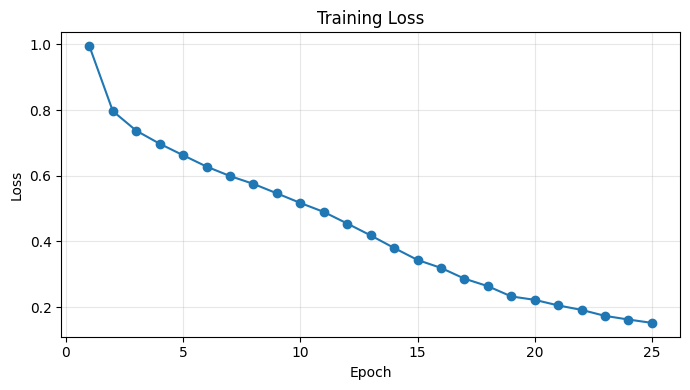

Saved figure: /kaggle/working/reports/training_loss_curve.png


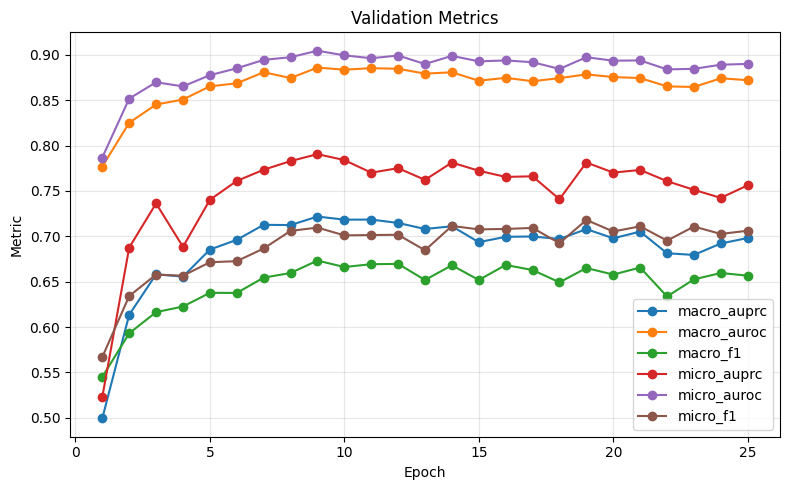

Saved figure: /kaggle/working/reports/validation_metrics_curve.png


In [75]:
def plot_training_history(history_path: Path):
    hist = pd.read_csv(history_path)
    display(hist)

    plt.figure(figsize=(7,4))
    plt.plot(hist["epoch"], hist["train_loss"], marker="o")
    plt.title("Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True, alpha=0.3)
    save_fig(REPORT_DIR / "training_loss_curve.png")

    metric_cols = [c for c in ["macro_auprc", "macro_auroc", "macro_f1", "micro_auprc", "micro_auroc", "micro_f1"] if c in hist.columns]
    plt.figure(figsize=(8,5))
    for c in metric_cols:
        plt.plot(hist["epoch"], hist[c], marker="o", label=c)
    plt.title("Validation Metrics")
    plt.xlabel("Epoch")
    plt.ylabel("Metric")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_fig(REPORT_DIR / "validation_metrics_curve.png")

plot_training_history(history_path)

## 18. Resume training from last checkpoint

Chỉ đổi `RESUME = True` nếu Kaggle bị ngắt và file checkpoint còn tồn tại.

In [76]:
RESUME = False

if RESUME and last_model_path.exists():
    model = build_convnextv2(num_classes=len(LABEL_NAMES), pretrained=False).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    ckpt = load_checkpoint(last_model_path, model=model, optimizer=optimizer)
    print("Resumed from epoch:", ckpt["epoch"])
    print("Best metric so far:", ckpt["best_metric"])
else:
    print("RESUME is False or last checkpoint does not exist. Nothing loaded.")

RESUME is False or last checkpoint does not exist. Nothing loaded.


## 19. Load best model and evaluate test fold 10

Lưu `test_metrics.csv`, `per_class_metrics.csv`, `test_predictions.csv`.

In [77]:
if not best_model_path.exists():
    print("Best checkpoint does not exist. Saving current model as best for debug continuity.")
    save_checkpoint(best_model_path, model, optimizer, epoch=0, best_metric=np.nan)

best_model = build_convnextv2(num_classes=len(LABEL_NAMES), pretrained=False).to(DEVICE)
best_ckpt = load_checkpoint(best_model_path, model=best_model, optimizer=None)
threshold_dict = best_ckpt.get("threshold", {label: THRESHOLD_DEFAULT for label in LABEL_NAMES})
print("Loaded best model:", best_model_path)
print("Checkpoint epoch:", best_ckpt.get("epoch"))
print("Best val metric:", best_ckpt.get("best_metric"))
print("Thresholds:", threshold_dict)

y_test, p_test, test_ids, test_paths = predict_loader(best_model, test_loader)
test_metrics, per_class_df = compute_metrics(y_test, p_test, threshold=THRESHOLD_DEFAULT)

test_metrics_df = pd.DataFrame([test_metrics])
test_metrics_df.to_csv(REPORT_DIR / "test_metrics.csv", index=False)
per_class_df.to_csv(REPORT_DIR / "per_class_metrics.csv", index=False)

pred_df = pd.DataFrame({"ecg_id": test_ids, "image_path": test_paths})
for i, label in enumerate(LABEL_NAMES):
    pred_df[f"true_{label}"] = y_test[:, i]
    pred_df[f"prob_{label}"] = p_test[:, i]
    pred_df[f"pred_{label}"] = (p_test[:, i] >= threshold_dict.get(label, THRESHOLD_DEFAULT)).astype(int)
pred_df.to_csv(REPORT_DIR / "test_predictions.csv", index=False)

display(test_metrics_df)
display(per_class_df)
display(pred_df.head())

Loaded convnextv2_base | pretrained=False | num_classes=5
Loaded best model: /kaggle/working/models/best_model.pt
Checkpoint epoch: 9
Best val metric: 0.7217257030184403
Thresholds: {'NORM': 0.5499999999999999, 'MI': 0.6, 'STTC': 0.49999999999999994, 'CD': 0.65, 'HYP': 0.49999999999999994}


Predicting:   0%|          | 0/136 [00:00<?, ?it/s]

,macro_auroc,macro_auprc,macro_f1,macro_precision,macro_recall,micro_auroc,micro_auprc,micro_f1
0,0.886158,0.729724,0.669473,0.595645,0.777665,0.904978,0.798705,0.707458


,label,support,auroc,auprc,f1,precision,recall_sensitivity,specificity
0,NORM,964,0.931596,0.906474,0.840552,0.776605,0.915975,0.788157
1,MI,553,0.862119,0.696283,0.648523,0.568895,0.754069,0.803727
2,STTC,523,0.918528,0.797112,0.705788,0.608877,0.839388,0.828049
3,CD,498,0.894890,0.792617,0.701652,0.679849,0.724900,0.897898
4,HYP,263,0.823658,0.456137,0.450852,0.344000,0.653992,0.827368


,ecg_id,image_path,true_NORM,prob_NORM,pred_NORM,true_MI,prob_MI,pred_MI,true_STTC,prob_STTC,pred_STTC,true_CD,prob_CD,pred_CD,true_HYP,prob_HYP,pred_HYP
0,9,/kaggle/working/data/cwt_grid/ecg_9_cwt.png,1.0,0.970018,1,0.0,0.048586,0,0.0,0.009853,0,0.0,0.041299,0,0.0,0.026427,0
1,38,/kaggle/working/data/cwt_grid/ecg_38_cwt.png,1.0,0.430611,0,0.0,0.199694,0,0.0,0.062932,0,0.0,0.846295,1,0.0,0.042983,0
2,40,/kaggle/working/data/cwt_grid/ecg_40_cwt.png,1.0,0.817729,1,0.0,0.187211,0,0.0,0.069883,0,0.0,0.137623,0,0.0,0.321723,0
3,57,/kaggle/working/data/cwt_grid/ecg_57_cwt.png,1.0,0.988287,1,0.0,0.005383,0,0.0,0.003599,0,0.0,0.043557,0,0.0,0.026756,0
4,59,/kaggle/working/data/cwt_grid/ecg_59_cwt.png,1.0,0.964275,1,0.0,0.022743,0,0.0,0.006907,0,0.0,0.288843,0,0.0,0.019238,0


## 20. Visualize test metrics

Per-class metrics, probability distribution, prediction example.

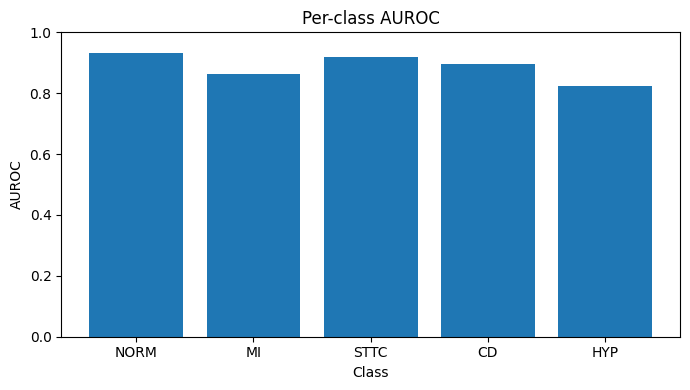

Saved figure: /kaggle/working/reports/per_class_auroc.png


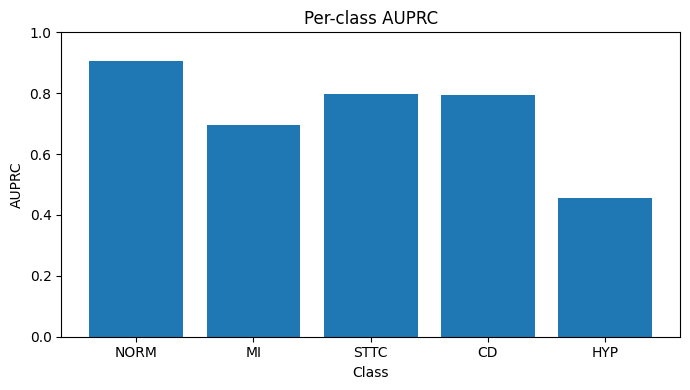

Saved figure: /kaggle/working/reports/per_class_auprc.png


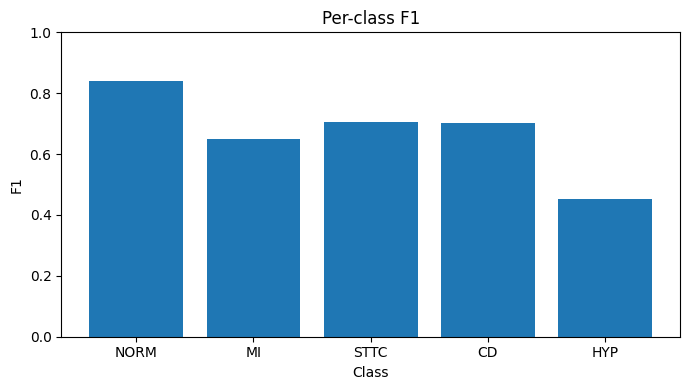

Saved figure: /kaggle/working/reports/per_class_f1.png


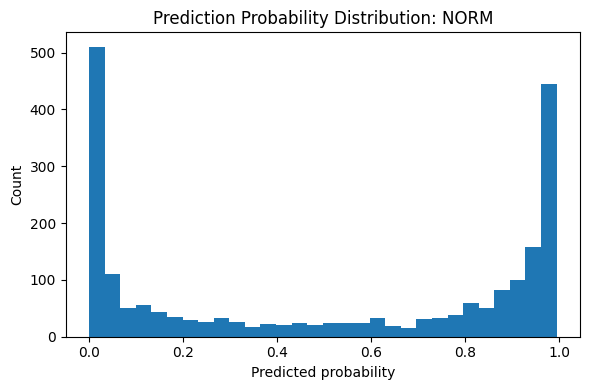

Saved figure: /kaggle/working/reports/prediction_distribution_NORM.png


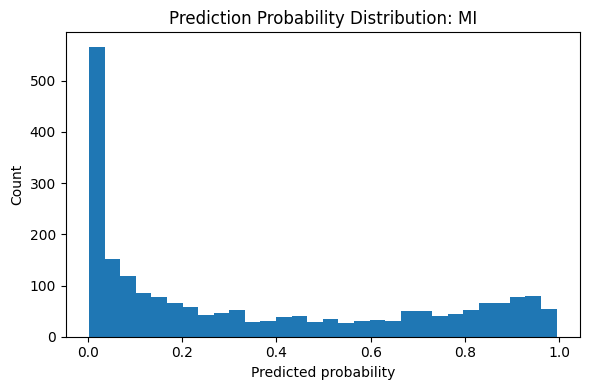

Saved figure: /kaggle/working/reports/prediction_distribution_MI.png


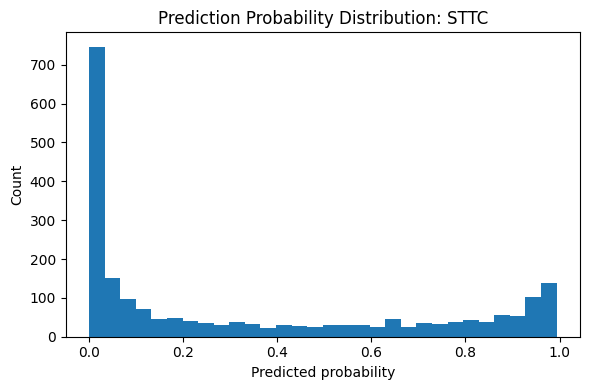

Saved figure: /kaggle/working/reports/prediction_distribution_STTC.png


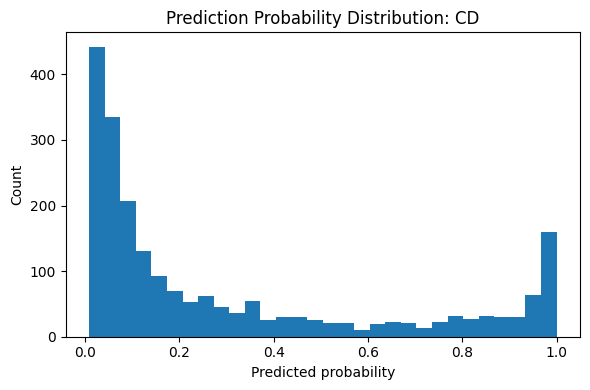

Saved figure: /kaggle/working/reports/prediction_distribution_CD.png


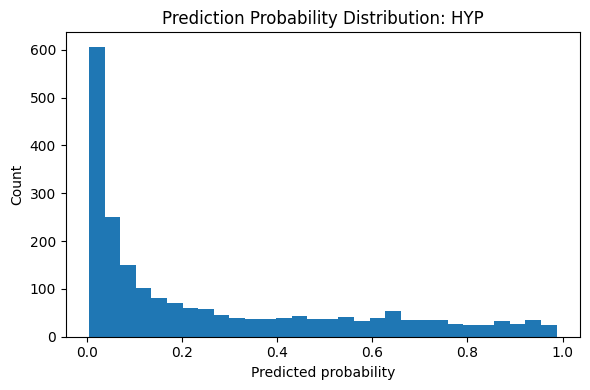

Saved figure: /kaggle/working/reports/prediction_distribution_HYP.png


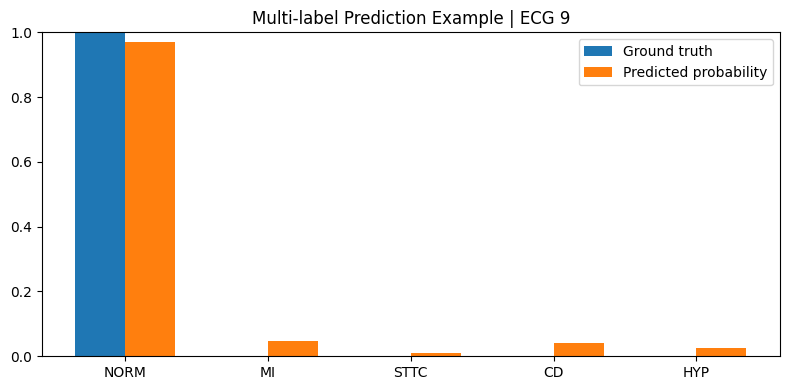

Saved figure: /kaggle/working/reports/prediction_example_ground_truth_vs_probability.png


In [78]:
def plot_per_class_metric(per_df: pd.DataFrame, metric: str):
    plt.figure(figsize=(7,4))
    plt.bar(per_df["label"], per_df[metric])
    plt.title(f"Per-class {metric.upper()}")
    plt.xlabel("Class")
    plt.ylabel(metric.upper())
    plt.ylim(0, 1)
    save_fig(REPORT_DIR / f"per_class_{metric}.png")

for metric in ["auroc", "auprc", "f1"]:
    plot_per_class_metric(per_class_df, metric)

for label in LABEL_NAMES:
    plt.figure(figsize=(6,4))
    plt.hist(pred_df[f"prob_{label}"], bins=30)
    plt.title(f"Prediction Probability Distribution: {label}")
    plt.xlabel("Predicted probability")
    plt.ylabel("Count")
    save_fig(REPORT_DIR / f"prediction_distribution_{label}.png")

if len(pred_df) > 0:
    example_pred = pred_df.iloc[0]
    gt = [example_pred[f"true_{label}"] for label in LABEL_NAMES]
    prob = [example_pred[f"prob_{label}"] for label in LABEL_NAMES]

    x = np.arange(len(LABEL_NAMES))
    width = 0.35
    plt.figure(figsize=(8,4))
    plt.bar(x - width/2, gt, width, label="Ground truth")
    plt.bar(x + width/2, prob, width, label="Predicted probability")
    plt.xticks(x, LABEL_NAMES)
    plt.ylim(0, 1)
    plt.title(f"Multi-label Prediction Example | ECG {int(example_pred['ecg_id'])}")
    plt.legend()
    save_fig(REPORT_DIR / "prediction_example_ground_truth_vs_probability.png")

## 21. Inference and visualization for one sample

Hiển thị raw ECG, CWT grid, ground truth và probabilities.

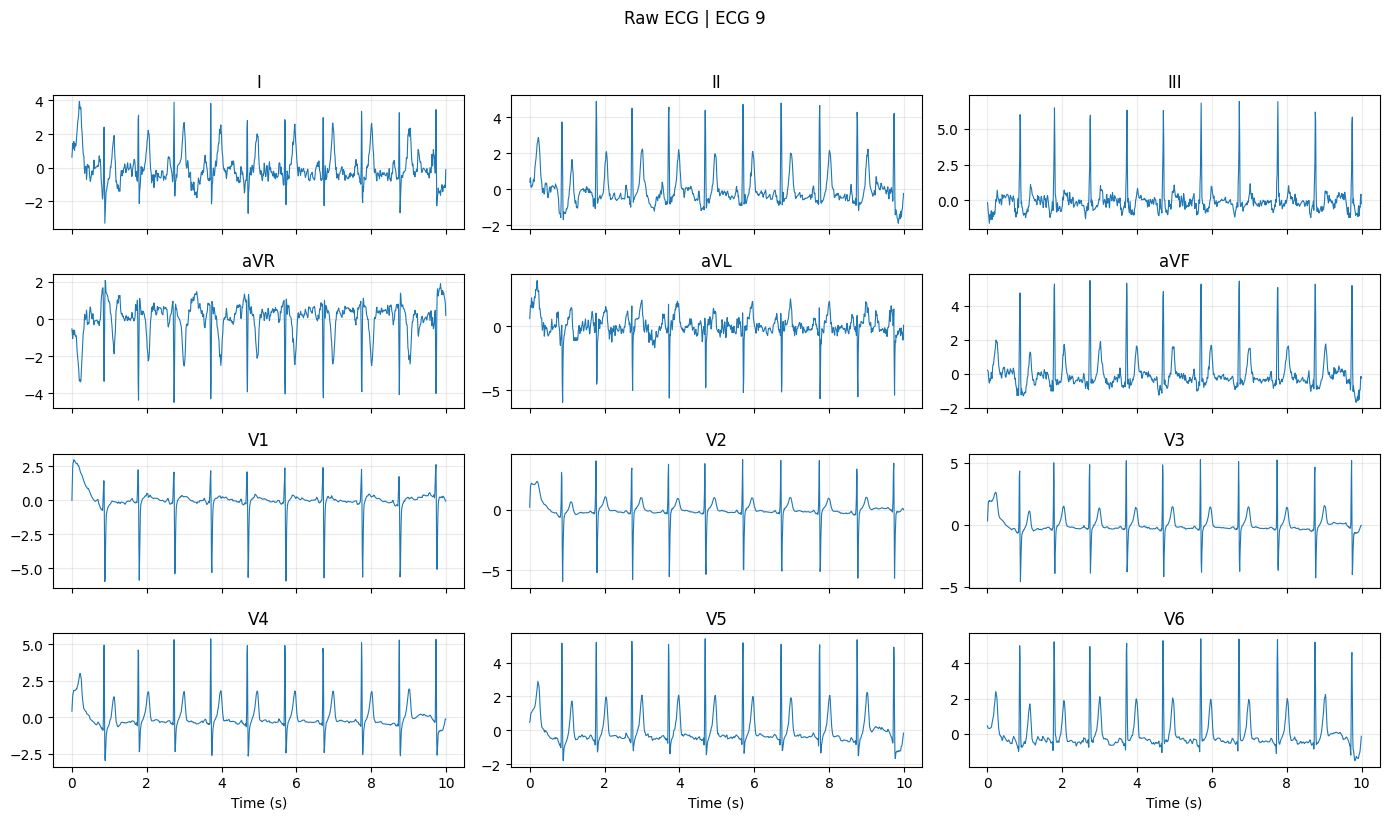

Saved: /kaggle/working/reports/inference_raw_ecg_9.png


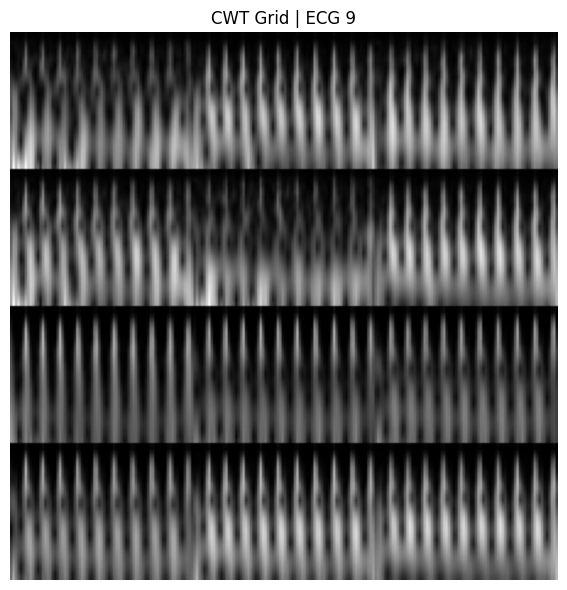

Saved figure: /kaggle/working/reports/inference_cwt_grid_9.png


,label,ground_truth,predicted_probability,threshold,predicted_label
0,NORM,1,0.970018,0.55,1
1,MI,0,0.048586,0.60,0
2,STTC,0,0.009853,0.50,0
3,CD,0,0.041299,0.65,0
4,HYP,0,0.026427,0.50,0


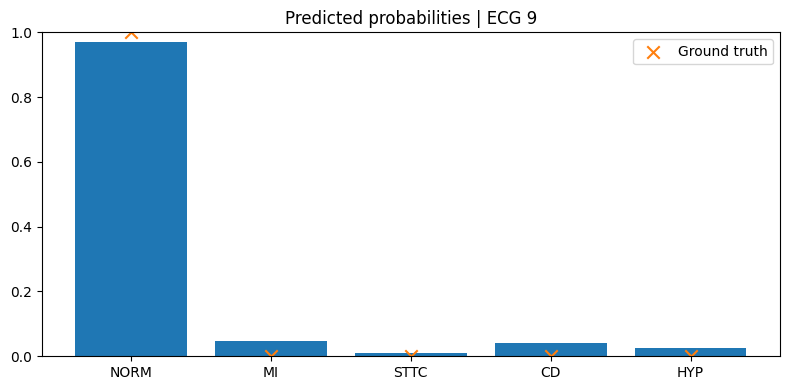

Saved figure: /kaggle/working/reports/inference_probabilities_9.png


In [79]:
@torch.no_grad()
def inference_one_sample(model, row, image_col="cwt_path"):
    img = Image.open(row[image_col]).convert("RGB")
    x = eval_transform(img).unsqueeze(0).to(DEVICE)
    logits = model(x).detach().cpu().numpy()[0]
    probs = sigmoid_np(logits)
    return probs

if len(test_df) > 0:
    row = test_df.iloc[0]
    raw_sig = load_preprocessed_ecg(row["record_path"])
    plot_spatial_12lead(raw_sig, f"Raw ECG | ECG {row['ecg_id']}", REPORT_DIR / f"inference_raw_ecg_{row['ecg_id']}.png")

    img = np.asarray(Image.open(row["cwt_path"]).convert("RGB"))
    plot_grid_image(img, f"CWT Grid | ECG {row['ecg_id']}", REPORT_DIR / f"inference_cwt_grid_{row['ecg_id']}.png")

    probs = inference_one_sample(best_model, row, image_col="cwt_path")
    inf_df = pd.DataFrame({
        "label": LABEL_NAMES,
        "ground_truth": row[LABEL_NAMES].values.astype(int),
        "predicted_probability": probs,
        "threshold": [threshold_dict.get(label, THRESHOLD_DEFAULT) for label in LABEL_NAMES],
    })
    inf_df["predicted_label"] = (inf_df["predicted_probability"] >= inf_df["threshold"]).astype(int)
    inf_df.to_csv(REPORT_DIR / "inference_one_sample.csv", index=False)
    display(inf_df)

    plt.figure(figsize=(8,4))
    plt.bar(inf_df["label"], inf_df["predicted_probability"])
    plt.scatter(inf_df["label"], inf_df["ground_truth"], marker="x", s=80, label="Ground truth")
    plt.ylim(0,1)
    plt.title(f"Predicted probabilities | ECG {row['ecg_id']}")
    plt.legend()
    save_fig(REPORT_DIR / f"inference_probabilities_{row['ecg_id']}.png")

## 22. Calibration curves and ECE

Tính Brier score, Expected Calibration Error và reliability curves.

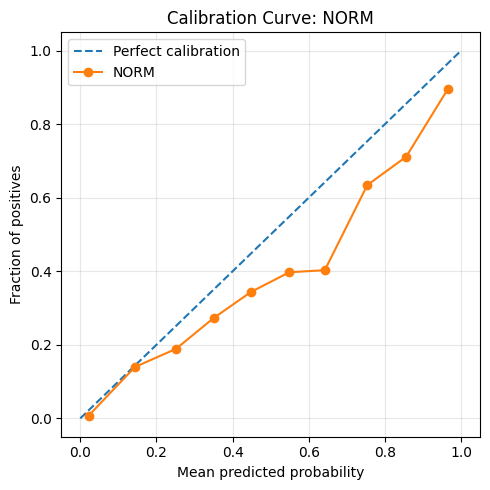

Saved figure: /kaggle/working/reports/calibration_curve_NORM.png


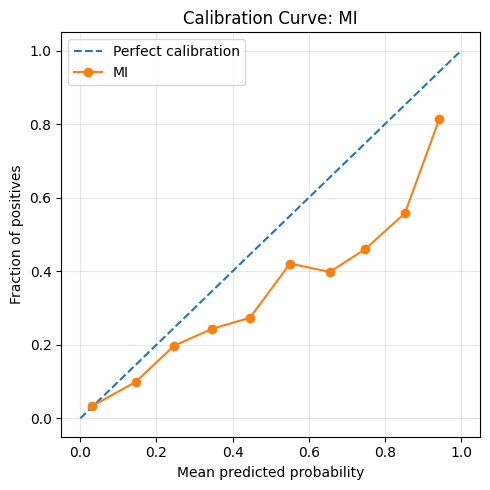

Saved figure: /kaggle/working/reports/calibration_curve_MI.png


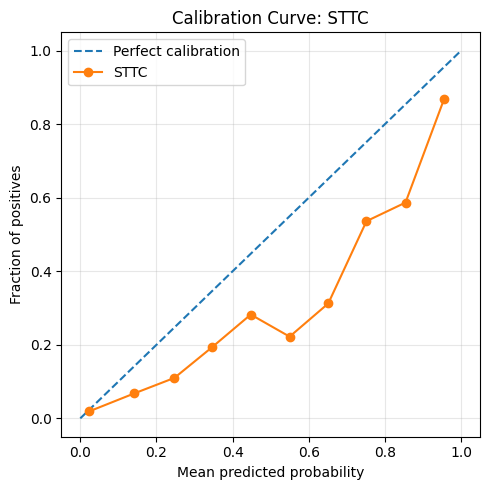

Saved figure: /kaggle/working/reports/calibration_curve_STTC.png


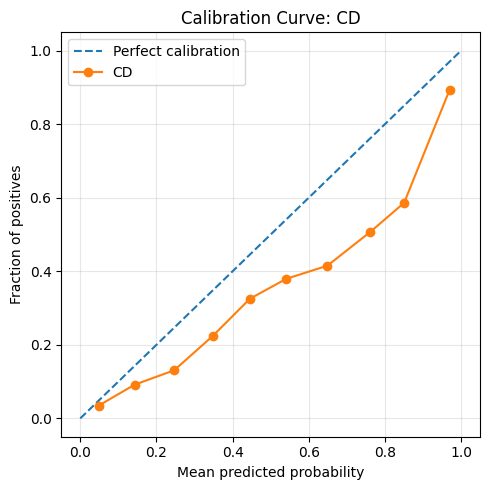

Saved figure: /kaggle/working/reports/calibration_curve_CD.png


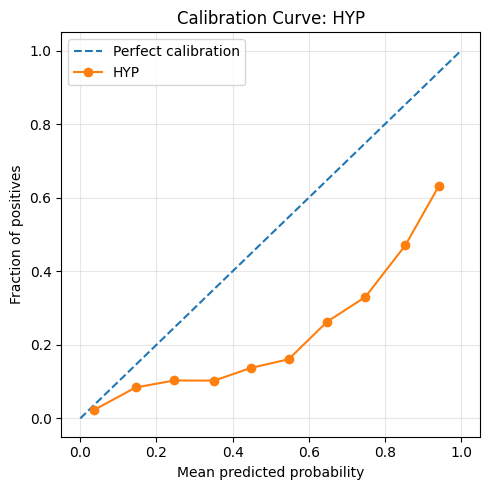

Saved figure: /kaggle/working/reports/calibration_curve_HYP.png


,label,brier_score,ece,support
0,NORM,0.111340,0.066902,964
1,MI,0.146148,0.097605,553
2,STTC,0.113868,0.095964,523
3,CD,0.106180,0.072781,498
4,HYP,0.129714,0.143747,263


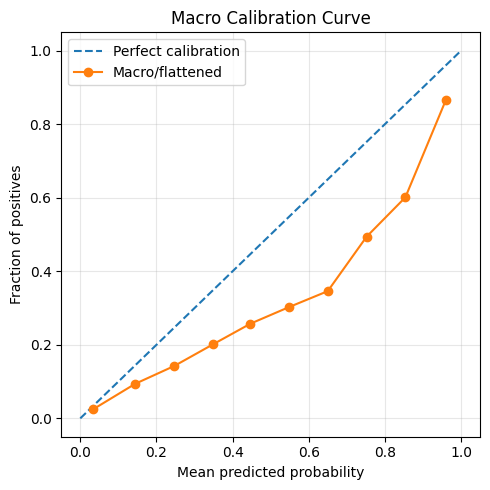

Saved figure: /kaggle/working/reports/calibration_curve_macro.png


In [80]:
def expected_calibration_error(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        mask = (y_prob > lo) & (y_prob <= hi) if i > 0 else (y_prob >= lo) & (y_prob <= hi)
        if mask.sum() == 0:
            continue
        acc = y_true[mask].mean()
        conf = y_prob[mask].mean()
        ece += (mask.sum() / len(y_prob)) * abs(acc - conf)
    return float(ece)

calibration_rows = []
for i, label in enumerate(LABEL_NAMES):
    yt = y_test[:, i]
    yp = p_test[:, i]
    try:
        bs = brier_score_loss(yt, yp)
    except Exception:
        bs = np.nan
    ece = expected_calibration_error(yt, yp, n_bins=10)

    calibration_rows.append({"label": label, "brier_score": bs, "ece": ece, "support": int(yt.sum())})

    if len(np.unique(yt)) >= 2:
        prob_true, prob_pred = calibration_curve(yt, yp, n_bins=10, strategy="uniform")
        plt.figure(figsize=(5,5))
        plt.plot([0,1], [0,1], linestyle="--", label="Perfect calibration")
        plt.plot(prob_pred, prob_true, marker="o", label=label)
        plt.xlabel("Mean predicted probability")
        plt.ylabel("Fraction of positives")
        plt.title(f"Calibration Curve: {label}")
        plt.legend()
        plt.grid(True, alpha=0.3)
        save_fig(REPORT_DIR / f"calibration_curve_{label}.png")

calibration_df = pd.DataFrame(calibration_rows)
calibration_df.to_csv(REPORT_DIR / "calibration_metrics.csv", index=False)
display(calibration_df)

try:
    yt_macro = y_test.ravel()
    yp_macro = p_test.ravel()
    prob_true, prob_pred = calibration_curve(yt_macro, yp_macro, n_bins=10, strategy="uniform")
    macro_brier = brier_score_loss(yt_macro, yp_macro)
    macro_ece = expected_calibration_error(yt_macro, yp_macro, n_bins=10)

    plt.figure(figsize=(5,5))
    plt.plot([0,1], [0,1], linestyle="--", label="Perfect calibration")
    plt.plot(prob_pred, prob_true, marker="o", label="Macro/flattened")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Fraction of positives")
    plt.title("Macro Calibration Curve")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_fig(REPORT_DIR / "calibration_curve_macro.png")

    pd.DataFrame([{"macro_brier_score": macro_brier, "macro_ece": macro_ece}]).to_csv(REPORT_DIR / "calibration_macro_metrics.csv", index=False)
except Exception as e:
    print("Macro calibration failed:", e)

## 23. Threshold optimization

Dùng validation set để tìm threshold tối ưu F1 cho từng class.

In [81]:
y_val, p_val, _, _ = predict_loader(best_model, val_loader)
opt_thresholds, opt_threshold_df = optimize_thresholds(y_val, p_val, LABEL_NAMES)
opt_threshold_df.to_csv(REPORT_DIR / "optimized_thresholds_from_validation.csv", index=False)
display(opt_threshold_df)

y_pred_opt = np.zeros_like(p_test).astype(int)
for i, label in enumerate(LABEL_NAMES):
    y_pred_opt[:, i] = (p_test[:, i] >= opt_thresholds[label]).astype(int)

opt_rows = []
for i, label in enumerate(LABEL_NAMES):
    opt_rows.append({
        "label": label,
        "threshold": opt_thresholds[label],
        "f1": f1_score(y_test[:, i], y_pred_opt[:, i], zero_division=0),
        "precision": precision_score(y_test[:, i], y_pred_opt[:, i], zero_division=0),
        "recall_sensitivity": recall_score(y_test[:, i], y_pred_opt[:, i], zero_division=0),
    })
opt_test_df = pd.DataFrame(opt_rows)
opt_test_df.to_csv(REPORT_DIR / "test_metrics_with_optimized_thresholds.csv", index=False)
display(opt_test_df)

Predicting:   0%|          | 0/135 [00:00<?, ?it/s]

,label,best_threshold,best_f1
0,NORM,0.55,0.837278
1,MI,0.60,0.668896
2,STTC,0.50,0.704969
3,CD,0.65,0.723404
4,HYP,0.50,0.450067


,label,threshold,f1,precision,recall_sensitivity
0,NORM,0.55,0.843128,0.792694,0.900415
1,MI,0.60,0.633081,0.590909,0.681736
2,STTC,0.50,0.705788,0.608877,0.839388
3,CD,0.65,0.695745,0.739819,0.656627
4,HYP,0.50,0.450852,0.344000,0.653992


## 24. Explainability: Grad-CAM-style heatmap for ConvNeXt-Tiny

Heatmap cho biết vùng ảnh CWT grid ảnh hưởng đến logit của class. Đây là explainability gần đúng, không thay thế diễn giải lâm sàng.

In [82]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.fwd_handle = self.target_layer.register_forward_hook(self.forward_hook)
        self.bwd_handle = self.target_layer.register_full_backward_hook(self.backward_hook)

    def forward_hook(self, module, inp, out):
        self.activations = out.detach()

    def backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def remove(self):
        self.fwd_handle.remove()
        self.bwd_handle.remove()

    def __call__(self, x, class_idx):
        self.model.zero_grad(set_to_none=True)
        logits = self.model(x)
        score = logits[:, class_idx].sum()
        score.backward(retain_graph=True)

        acts = self.activations
        grads = self.gradients

        if acts is None or grads is None:
            raise RuntimeError("GradCAM hooks did not capture activations/gradients.")

        weights = grads.mean(dim=(2, 3), keepdim=True)
        cam = (weights * acts).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = torch.nn.functional.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam

def overlay_heatmap_on_image(img_rgb: np.ndarray, heatmap: np.ndarray, alpha: float = 0.45):
    img = img_rgb.astype(np.float32) / 255.0
    cmap = plt.get_cmap("jet")
    heat_rgb = cmap(heatmap)[:, :, :3]
    overlay = (1 - alpha) * img + alpha * heat_rgb
    return np.clip(overlay, 0, 1)

def explain_one_sample(model, row, class_label: str, image_col="cwt_path"):
    class_idx = LABEL_NAMES.index(class_label)
    img_pil = Image.open(row[image_col]).convert("RGB")
    img_np = np.asarray(img_pil.resize((IMAGE_SIZE, IMAGE_SIZE)))

    x = eval_transform(img_pil).unsqueeze(0).to(DEVICE)
    model.eval()

    target_layer = model.features[-1]
    cam_engine = GradCAM(model, target_layer)

    try:
        heatmap = cam_engine(x, class_idx)
    finally:
        cam_engine.remove()

    overlay = overlay_heatmap_on_image(img_np, heatmap)

    fig, axes = plt.subplots(1, 3, figsize=(15,5))
    axes[0].imshow(img_np)
    axes[0].set_title("Original CWT grid")
    axes[0].axis("off")

    axes[1].imshow(heatmap, cmap="jet")
    axes[1].set_title(f"Heatmap for {class_label}")
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title("Overlay")
    axes[2].axis("off")

    save_path = REPORT_DIR / f"explainability_ecg{int(row['ecg_id'])}_{class_label}.png"
    plt.tight_layout()
    plt.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", save_path)

for label in LABEL_NAMES:
    candidates = test_df[test_df[label] == 1]
    if len(candidates) == 0:
        continue
    row = candidates.iloc[0]
    try:
        explain_one_sample(best_model, row, class_label=label, image_col="cwt_path")
    except Exception as e:
        print(f"Explainability failed for {label}:", e)

Explainability failed for NORM: 'ConvNeXt' object has no attribute 'features'
Explainability failed for MI: 'ConvNeXt' object has no attribute 'features'
Explainability failed for STTC: 'ConvNeXt' object has no attribute 'features'
Explainability failed for CD: 'ConvNeXt' object has no attribute 'features'
Explainability failed for HYP: 'ConvNeXt' object has no attribute 'features'


## 25. Ablation study: CWT vs STFT

Ablation subset/full tùy cấu hình.

Full mode ablation skipped. Set RUN_ABLATION_FULL=True to run.


,representation,macro_auprc,macro_auroc,macro_f1,note
0,CWT,0.729724,0.886158,0.669473,Main model result only; ablation not run.


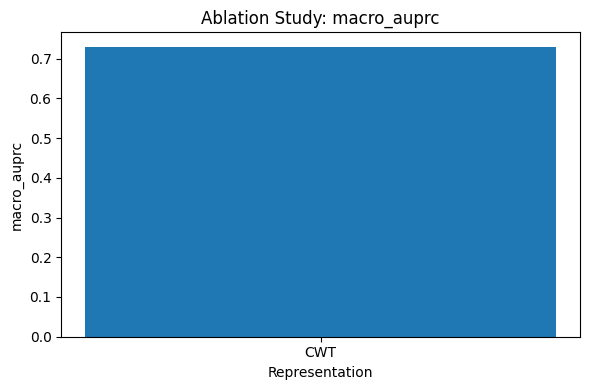

Saved figure: /kaggle/working/reports/ablation_results_bar_chart.png


In [83]:
RUN_ABLATION = True
RUN_ABLATION_FULL = False
ABLATION_EPOCHS_DEBUG = 2
ABLATION_EPOCHS_FULL = 5

def run_quick_ablation(image_col: str, representation_name: str, epochs: int):
    print(f"\nRunning ablation: {representation_name} | image_col={image_col} | epochs={epochs}")
    tr_loader, va_loader, te_loader, tr_df, va_df, te_df = make_loaders(manifest_images, image_col=image_col, batch_size=BATCH_SIZE)

    ab_model = build_convnextv2(num_classes=len(LABEL_NAMES), pretrained=False).to(DEVICE)
    ab_pos_weight = compute_pos_weight(tr_df, LABEL_NAMES).to(DEVICE)
    ab_criterion = nn.BCEWithLogitsLoss(pos_weight=ab_pos_weight)
    ab_optimizer = torch.optim.AdamW(ab_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    best_val = -np.inf
    ab_best_state = None
    for ep in range(1, epochs + 1):
        loss = train_one_epoch(ab_model, tr_loader, ab_criterion, ab_optimizer)
        yv, pv, _, _ = predict_loader(ab_model, va_loader)
        m, _ = compute_metrics(yv, pv)
        val_score = m.get("macro_auprc", np.nan)
        print(f"[{representation_name}] epoch={ep} loss={loss:.4f} val_macro_auprc={val_score}")
        if not np.isnan(val_score) and val_score > best_val:
            best_val = val_score
            ab_best_state = {k: v.detach().cpu() for k, v in ab_model.state_dict().items()}

    if ab_best_state is not None:
        ab_model.load_state_dict(ab_best_state)

    yt, pt, _, _ = predict_loader(ab_model, te_loader)
    test_m, test_per = compute_metrics(yt, pt)
    row = {"representation": representation_name, **test_m}
    return row, test_per

ablation_results = []
if RUN_ABLATION:
    ab_epochs = ABLATION_EPOCHS_DEBUG if RUN_MODE == "debug" else ABLATION_EPOCHS_FULL
    if RUN_MODE == "debug" or RUN_ABLATION_FULL:
        for image_col, rep_name in [("cwt_path", "CWT"), ("stft_path", "STFT")]:
            try:
                row, per = run_quick_ablation(image_col, rep_name, epochs=ab_epochs)
                ablation_results.append(row)
                per.to_csv(REPORT_DIR / f"ablation_per_class_{rep_name}.csv", index=False)
            except Exception as e:
                print(f"Ablation failed for {rep_name}:", e)
    else:
        print("Full mode ablation skipped. Set RUN_ABLATION_FULL=True to run.")

if len(ablation_results) > 0:
    ablation_df = pd.DataFrame(ablation_results)
else:
    ablation_df = pd.DataFrame([{
        "representation": "CWT",
        "macro_auprc": test_metrics.get("macro_auprc", np.nan),
        "macro_auroc": test_metrics.get("macro_auroc", np.nan),
        "macro_f1": test_metrics.get("macro_f1", np.nan),
        "note": "Main model result only; ablation not run."
    }])

ablation_df.to_csv(REPORT_DIR / "ablation_results.csv", index=False)
display(ablation_df)

metric_to_plot = "macro_auprc" if "macro_auprc" in ablation_df.columns else ablation_df.columns[-1]
plt.figure(figsize=(6,4))
plt.bar(ablation_df["representation"], ablation_df[metric_to_plot])
plt.title(f"Ablation Study: {metric_to_plot}")
plt.xlabel("Representation")
plt.ylabel(metric_to_plot)
save_fig(REPORT_DIR / "ablation_results_bar_chart.png")

## 26. Generate research report markdown

Tạo `VinStroke_ECG_Research_Report.md` tại `/kaggle/working/reports`.

In [84]:
def safe_read_csv(path: Path):
    if path.exists():
        return pd.read_csv(path)
    return pd.DataFrame()

def markdown_table_from_csv(path: Path, max_rows=20):
    df = safe_read_csv(path)
    if df.empty:
        return "_Not available._"
    return df.head(max_rows).to_markdown(index=False)

def generate_report():
    now = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    report_path = REPORT_DIR / "VinStroke_ECG_Research_Report.md"

    md_text = f"""# VinStroke-ECG Research Report

Generated at: {now}

## 1. Study Overview

VinStroke-ECG is designed as a hierarchical multi-label 12-lead ECG interpretation framework using multi-representation time-frequency vision models.

The model does not directly predict stroke. It detects ECG abnormalities and rhythm-related findings associated with cardiovascular and stroke risk, especially AFIB.

## 2. Configuration

```json
{json.dumps(CONFIG, indent=2)}
```

## 3. Dataset Summary

{markdown_table_from_csv(REPORT_DIR / "dataset_summary.csv")}

## 4. Split Distribution

{markdown_table_from_csv(REPORT_DIR / "split_distribution.csv")}

![Split Distribution](split_distribution.png)

## 5. Diagnostic Superclass Distribution

{markdown_table_from_csv(REPORT_DIR / "class_counts_percentages.csv")}

![Class Counts](class_counts.png)

![Class Percentages](class_percentages.png)

## 6. Label Co-occurrence

![Label Co-occurrence Matrix](label_cooccurrence_matrix.png)

## 7. Top SCP Statements

{markdown_table_from_csv(REPORT_DIR / "top_scp_statements.csv")}

![Top SCP Statements](top_scp_statements.png)

## 8. Raw ECG and Time-Frequency Visualization

Examples are saved in the reports folder:
- `raw_12lead_*.png`
- `spatial_12lead_*.png`
- `*_cwt_lead_II.png`
- `*_stft_lead_II.png`
- `*_cwt_grid.png`
- `*_stft_grid.png`

## 9. Training Curves

![Training Loss](training_loss_curve.png)

![Validation Metrics](validation_metrics_curve.png)

## 10. Test Metrics

{markdown_table_from_csv(REPORT_DIR / "test_metrics.csv")}

## 11. Per-Class Metrics

{markdown_table_from_csv(REPORT_DIR / "per_class_metrics.csv")}

![Per-class AUROC](per_class_auroc.png)

![Per-class AUPRC](per_class_auprc.png)

![Per-class F1](per_class_f1.png)

## 12. Calibration

{markdown_table_from_csv(REPORT_DIR / "calibration_metrics.csv")}

![Macro Calibration](calibration_curve_macro.png)

## 13. Threshold Optimization

{markdown_table_from_csv(REPORT_DIR / "optimized_thresholds_from_validation.csv")}

## 14. Explainability

Explainability outputs are saved as:
- `explainability_ecg*_NORM.png`
- `explainability_ecg*_MI.png`
- `explainability_ecg*_STTC.png`
- `explainability_ecg*_CD.png`
- `explainability_ecg*_HYP.png`

These heatmaps are Grad-CAM-style approximations over the CWT 12-lead grid.

## 15. Ablation Study

{markdown_table_from_csv(REPORT_DIR / "ablation_results.csv")}

![Ablation Results](ablation_results_bar_chart.png)

## 16. Limitations

1. PTB-XL does not contain direct stroke outcome labels; therefore, this model must not be interpreted as a direct stroke-risk predictor.
2. Class imbalance may affect rare-label performance.
3. Debug mode results are not research-valid and only verify the pipeline.
4. External validation is required before claiming robustness across domains.
5. Grad-CAM-style heatmaps provide model attention evidence, not clinical causality.

## 17. Artifact Locations

- Best model: `/kaggle/working/models/best_model.pt`
- Last model: `/kaggle/working/models/last_model.pt`
- Manifests: `/kaggle/working/manifests`
- Reports: `/kaggle/working/reports`
- Final artifacts: `/kaggle/working/final_artifacts`
"""
    report_path.write_text(md_text, encoding="utf-8")
    print("Saved report:", report_path)
    return report_path

report_path = generate_report()
print(report_path.read_text(encoding="utf-8")[:2000])

Saved report: /kaggle/working/reports/VinStroke_ECG_Research_Report.md
# VinStroke-ECG Research Report

Generated at: 2026-07-09 22:05:59

## 1. Study Overview

VinStroke-ECG is designed as a hierarchical multi-label 12-lead ECG interpretation framework using multi-representation time-frequency vision models.

The model does not directly predict stroke. It detects ECG abnormalities and rhythm-related findings associated with cardiovascular and stroke risk, especially AFIB.

## 2. Configuration

```json
{
  "run_mode": "full",
  "debug_limit": 20,
  "epochs": 25,
  "batch_size": 16,
  "sampling_rate": 100,
  "signal_length": 1000,
  "image_size": 224,
  "pretrained": true,
  "model_name": "convnextv2_base",
  "label_names": [
    "NORM",
    "MI",
    "STTC",
    "CD",
    "HYP"
  ],
  "rhythm_labels": [
    "AFIB"
  ],
  "lr": 0.0001,
  "weight_decay": 0.0001,
  "cwt_wavelet": "morl",
  "cwt_scales": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    1

## 27. Export final artifacts

Gom outputs vào `/kaggle/working/final_artifacts` và zip.

In [85]:
def copytree_contents(src: Path, dst: Path):
    dst.mkdir(parents=True, exist_ok=True)
    if not src.exists():
        return
    for item in src.iterdir():
        target = dst / item.name
        if item.is_dir():
            if target.exists():
                shutil.rmtree(target)
            shutil.copytree(item, target)
        else:
            shutil.copy2(item, target)

if FINAL_DIR.exists():
    shutil.rmtree(FINAL_DIR)
FINAL_DIR.mkdir(parents=True, exist_ok=True)

copytree_contents(MODEL_DIR, FINAL_DIR / "models")
copytree_contents(REPORT_DIR, FINAL_DIR / "reports")
copytree_contents(MANIFEST_DIR, FINAL_DIR / "manifests")

if report_path.exists():
    shutil.copy2(report_path, FINAL_DIR / "VinStroke_ECG_Research_Report.md")

(FINAL_DIR / "config.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")

zip_path = WORK_DIR / "VinStroke_ECG_artifacts.zip"
if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file_path in FINAL_DIR.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, arcname=file_path.relative_to(FINAL_DIR))

print("Created zip:", zip_path)
print("\nFiles in zip:")
with zipfile.ZipFile(zip_path, "r") as zf:
    names = zf.namelist()
    for name in names[:200]:
        print(" -", name)
    if len(names) > 200:
        print(f"... and {len(names)-200} more files")

Created zip: /kaggle/working/VinStroke_ECG_artifacts.zip

Files in zip:
 - config.json
 - VinStroke_ECG_Research_Report.md
 - reports/inference_one_sample.csv
 - reports/spatial_12lead_MI_ecg8.png
 - reports/explainability_ecg65_CD.png
 - reports/validation_optimized_thresholds.csv
 - reports/class_percentages.png
 - reports/sex_distribution.png
 - reports/prediction_distribution_NORM.png
 - reports/spatial_12lead_NORM_ecg1.png
 - reports/ecg1_stft_grid.png
 - reports/prediction_distribution_MI.png
 - reports/raw_12lead_CD_ecg32.png
 - reports/test_predictions.csv
 - reports/ecg1_cwt_lead_II.png
 - reports/test_metrics_with_optimized_thresholds.csv
 - reports/calibration_curve_MI.png
 - reports/raw_12lead_AFIB_ecg152.png
 - reports/sex_distribution.csv
 - reports/image_generation_errors.csv
 - reports/explainability_ecg63_MI.png
 - reports/dataset_summary.csv
 - reports/spatial_12lead_CD_ecg32.png
 - reports/representative_samples.csv
 - reports/training_loss_curve.png
 - reports/ablat

## 28. How to switch from debug to full

Sau khi debug pass, quay lại cell **Setup configuration** và đổi:

```python
RUN_MODE = "full"
EPOCHS_FULL = 15
```

Nếu có nhiều thời gian/GPU hơn:

```python
EPOCHS_FULL = 30
BATCH_SIZE_FULL = 32
PRETRAINED = False
```

Khuyến nghị:
1. Debug với `DEBUG_LIMIT = 20`.
2. Debug với `DEBUG_LIMIT = 200`.
3. Full mode generate CWT images.
4. Full mode train CWT model.
5. Sau đó mới chạy ablation STFT hoặc external validation.

Nếu Kaggle bị ngắt:
- Chạy lại setup.
- Chạy lại các cell load manifest/images.
- Dùng cell resume từ `/kaggle/working/models/last_model.pt` nếu file còn trong session.

In [92]:
from pathlib import Path
from IPython.display import FileLink, display
import zipfile
import os

WORKING_DIR = Path("/kaggle/working")
ZIP_PATH = WORKING_DIR / "VinStroke_ECG_artifacts.zip"

required_files = [
    WORKING_DIR / "models" / "best_model.pt",
    WORKING_DIR / "models" / "last_model.pt",
]

print("Checking critical files...")
for f in required_files:
    if f.exists():
        size_mb = f.stat().st_size / (1024 ** 2)
        print(f"FOUND: {f} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING: {f}")

# If final zip does not exist, create it safely from existing folders/files
if not ZIP_PATH.exists():
    print("\nFinal zip not found. Creating zip safely...")

    folders_to_zip = [
        WORKING_DIR / "models",
        WORKING_DIR / "reports",
        WORKING_DIR / "manifests",
        WORKING_DIR / "final_artifacts",
    ]

    extra_files = [
        WORKING_DIR / "config.json",
        WORKING_DIR / "VinStroke_ECG_Research_Report.md",
    ]

    with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
        for folder in folders_to_zip:
            if folder.exists():
                for file in folder.rglob("*"):
                    if file.is_file():
                        zf.write(file, arcname=file.relative_to(WORKING_DIR))

        for file in extra_files:
            if file.exists():
                zf.write(file, arcname=file.relative_to(WORKING_DIR))

    print(f"Created zip: {ZIP_PATH}")
else:
    print(f"\nFinal zip already exists: {ZIP_PATH}")

zip_size_mb = ZIP_PATH.stat().st_size / (1024 ** 2)
print(f"Zip size: {zip_size_mb:.2f} MB")

print("\nFiles inside zip:")
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    names = zf.namelist()
    for name in names[:50]:
        print(" -", name)
    if len(names) > 50:
        print(f" ... and {len(names) - 50} more files")

print("\nDownload link:")
display(FileLink(str(ZIP_PATH)))

Checking critical files...
FOUND: /kaggle/working/models/best_model.pt (1004.07 MB)
FOUND: /kaggle/working/models/last_model.pt (1004.07 MB)

Final zip already exists: /kaggle/working/VinStroke_ECG_artifacts.zip
Zip size: 1874.96 MB

Files inside zip:
 - config.json
 - VinStroke_ECG_Research_Report.md
 - reports/inference_one_sample.csv
 - reports/spatial_12lead_MI_ecg8.png
 - reports/explainability_ecg65_CD.png
 - reports/validation_optimized_thresholds.csv
 - reports/class_percentages.png
 - reports/sex_distribution.png
 - reports/prediction_distribution_NORM.png
 - reports/spatial_12lead_NORM_ecg1.png
 - reports/ecg1_stft_grid.png
 - reports/prediction_distribution_MI.png
 - reports/raw_12lead_CD_ecg32.png
 - reports/test_predictions.csv
 - reports/ecg1_cwt_lead_II.png
 - reports/test_metrics_with_optimized_thresholds.csv
 - reports/calibration_curve_MI.png
 - reports/raw_12lead_AFIB_ecg152.png
 - reports/sex_distribution.csv
 - reports/image_generation_errors.csv
 - reports/explain

/kaggle/working/VinStroke_ECG_artifacts.zip

In [94]:
import os
from pathlib import Path
from IPython.display import FileLink, display, HTML

os.chdir("/kaggle/working")

zip_name = "VinStroke_ECG_artifacts.zip"
zip_path = Path("/kaggle/working") / zip_name

if zip_path.exists():
    print("ZIP exists:", zip_path)
    print(f"Size: {zip_path.stat().st_size / (1024 ** 2):.2f} MB")
    
    print("\nRelative FileLink:")
    display(FileLink(zip_name))
    
    print("\nHTML download link:")
    display(HTML(f'<a href="{zip_name}" download>Download {zip_name}</a>'))
else:
    print("ZIP not found.")

ZIP exists: /kaggle/working/VinStroke_ECG_artifacts.zip
Size: 1874.96 MB

Relative FileLink:


/kaggle/working/VinStroke_ECG_artifacts.zip


HTML download link:
